# Riesgo de evento adverso en el primer año después de un trasplante de médula ósea

Proyecto final del módulo de Machine Learning. Especialización en Inteligencia Artificial, Universidad Pedagógica y Tecnológica de Colombia.

Autor: [Nombre]

Objetivo: estimar, con la información disponible antes del trasplante, la probabilidad de que un paciente tenga un evento adverso en los primeros 12 meses, y explicar de qué depende esa estimación.

## Índice

1. Problema y contexto
2. Datos y diccionario de variables
3. Calidad y limpieza de los datos
    - 3.1 Valores nulos por variable
    - 3.2 Limpieza: de df_raw a df_clean
4. Variable objetivo: de tiempo hasta el evento a clasificación
5. Análisis exploratorio
    - 5.1 Edad del paciente y del donante
    - 5.2 Variables clínicas principales
    - 5.3 Compatibilidad HLA y PCA
    - 5.4 Quién tiene datos vacíos
    - 5.5 Datos vacíos y seguimiento en el tiempo
    - 5.6 Conclusiones del análisis exploratorio
6. Preparación de datos: Pipeline, imputación y reducción de dimensión
7. Balanceo de clases
8. Comparación de modelos
9. Ajuste de hiperparámetros con GridSearchCV
10. Evaluación final en df_test
    - 10.1 Matriz de confusión y curvas
    - 10.2 Riesgo por deciles
    - 10.3 Desempeño por grupo racial
    - 10.4 Desempeño por subgrupo clínico
11. Análisis a 6, 12 y 18 meses
12. Explicabilidad con SHAP
13. Exportación del modelo
14. Conclusiones

# 1. Problema y contexto

El trasplante alogénico de células hematopoyéticas (HCT, conocido como trasplante de médula ósea) reemplaza la médula enferma de un paciente con células sanas de un donante. Puede curar leucemias y otras enfermedades graves de la sangre, pero en el primer año muchos pacientes tienen un evento adverso.

Qué es el evento en este proyecto: el diccionario de la competencia llama a la variable resultado efs, supervivencia libre de eventos. Un paciente con efs igual a 1 perdió esa condición, es decir, tuvo un evento grave después del trasplante (en trasplante este indicador agrupa sucesos como la recaída de la enfermedad, la falla del injerto o la muerte). efs_time dice cuántos meses pasaron hasta ese evento o hasta el último control. En todo el notebook, "evento" o "evento en 12 meses" se refiere a esto.

Cómo se mide el éxito: la métrica principal es el AUC-ROC. Responde a esta pregunta: si se toma al azar un paciente que tuvo el evento y otro que no, ¿con qué frecuencia el modelo le asigna más riesgo al primero? Un AUC de 0.5 es lanzar una moneda y 1.0 es acertar siempre. Se complementa con el recall (cuántos eventos reales detecta el modelo), la precision (cuántas alertas son correctas) y la calibración (si un riesgo de 30% significa de verdad 3 de cada 10 pacientes).

# 2. Datos y diccionario de variables

Los datos son los de la competencia CIBMTR, Equity in post-HCT Survival Predictions, de Kaggle: 28,800 pacientes con 57 variables registradas antes del trasplante, un identificador y dos columnas de resultado. Los archivos train.csv y data_dictionary.csv se guardan en la carpeta data/ del proyecto.

Los nombres originales son abreviaturas en inglés difíciles de leer (por ejemplo hla_match_drb1_low o tce_imm_match). Se renombraron en español a partir de la descripción de cada variable en el diccionario oficial de la competencia, publicado en https://www.kaggle.com/competitions/equity-post-HCT-survival-predictions/data. Los valores de cada variable se dejan como vienen en la fuente.

In [1]:
# Librerias del proyecto. En Google Colab todas vienen instaladas, incluidas xgboost y shap.
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
import xgboost
import shap
from scipy import stats

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, AdaBoostClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, roc_curve, precision_recall_curve,
                             recall_score, precision_score, brier_score_loss)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEMILLA = 42
np.random.seed(SEMILLA)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
AZUL, ROJO, GRIS, VERDE, OCRE = "#2F5D8A", "#B5443B", "#8C8C8C", "#3E7C5A", "#C08A2B"
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| shap", shap.__version__)

pandas 3.0.5 | scikit-learn 1.9.1 | xgboost 3.0.5 | shap 0.0.0+local


In [2]:
# Los archivos de la competencia van en la carpeta data/ del proyecto.
df_raw = pd.read_csv("data/train.csv")
df_diccionario = pd.read_csv("data/data_dictionary.csv")
print(f"Pacientes: {df_raw.shape[0]:,} | Columnas: {df_raw.shape[1]}")
df_raw.head(3)

Pacientes: 28,800 | Columnas: 60


,ID,dri_score,psych_disturb,cyto_score,diabetes,hla_match_c_high,hla_high_res_8,tbi_status,arrhythmia,hla_low_res_6,graft_type,vent_hist,renal_issue,pulm_severe,prim_disease_hct,hla_high_res_6,cmv_status,hla_high_res_10,hla_match_dqb1_high,tce_imm_match,hla_nmdp_6,hla_match_c_low,rituximab,hla_match_drb1_low,hla_match_dqb1_low,prod_type,cyto_score_detail,conditioning_intensity,ethnicity,year_hct,obesity,mrd_hct,in_vivo_tcd,tce_match,hla_match_a_high,hepatic_severe,donor_age,prior_tumor,hla_match_b_low,peptic_ulcer,age_at_hct,hla_match_a_low,gvhd_proph,rheum_issue,sex_match,hla_match_b_high,race_group,comorbidity_score,karnofsky_score,hepatic_mild,tce_div_match,donor_related,melphalan_dose,hla_low_res_8,cardiac,hla_match_drb1_high,pulm_moderate,hla_low_res_10,efs,efs_time
0,0,N/A - non-malignant indication,No,NaN,No,NaN,NaN,No TBI,No,6.0,Bone marrow,No,No,No,IEA,6.0,+/+,NaN,2.0,NaN,6.0,2.0,No,2.0,2.0,BM,NaN,NaN,Not Hispanic or Latino,2016,No,NaN,Yes,NaN,2.0,No,NaN,No,2.0,No,9.942,2.0,FKalone,No,M-F,2.0,More than one race,0.0,90.0,No,NaN,Unrelated,"N/A, Mel not given",8.0,No,2.0,No,10.0,0.0,42.356
1,1,Intermediate,No,Intermediate,No,2.0,8.0,"TBI +- Other, >cGy",No,6.0,Peripheral blood,No,No,No,AML,6.0,+/+,10.0,2.0,P/P,6.0,2.0,No,2.0,2.0,PB,Intermediate,MAC,Not Hispanic or Latino,2008,No,Positive,No,Permissive,2.0,No,72.29,No,2.0,No,43.705,2.0,Other GVHD Prophylaxis,No,F-F,2.0,Asian,3.0,90.0,No,Permissive mismatched,Related,"N/A, Mel not given",8.0,No,2.0,Yes,10.0,1.0,4.672
2,2,N/A - non-malignant indication,No,NaN,No,2.0,8.0,No TBI,No,6.0,Bone marrow,No,No,No,HIS,6.0,+/+,10.0,2.0,P/P,6.0,2.0,No,2.0,2.0,BM,NaN,NaN,Not Hispanic or Latino,2019,No,NaN,Yes,NaN,2.0,No,NaN,No,2.0,No,33.997,2.0,Cyclophosphamide alone,No,F-M,2.0,More than one race,0.0,90.0,No,Permissive mismatched,Related,"N/A, Mel not given",8.0,No,2.0,No,10.0,0.0,19.793


In [3]:
# Nombres en español construidos a partir de la descripción de cada variable en el diccionario oficial.
NOMBRES = {
    "ID": "id", "efs": "evento", "efs_time": "meses_hasta_evento",
    "dri_score": "indice_riesgo_enfermedad", "psych_disturb": "trastorno_psiquiatrico", "cyto_score": "puntaje_citogenetico",
    "diabetes": "diabetes", "hla_match_c_high": "hla_c_alta_res", "hla_high_res_8": "hla_alta_res_8",
    "tbi_status": "irradiacion_corporal_total", "arrhythmia": "arritmia", "hla_low_res_6": "hla_baja_res_6",
    "graft_type": "tipo_injerto", "vent_hist": "antecedente_ventilacion", "renal_issue": "enfermedad_renal",
    "pulm_severe": "enfermedad_pulmonar_severa", "prim_disease_hct": "enfermedad_principal", "hla_high_res_6": "hla_alta_res_6",
    "cmv_status": "serologia_cmv", "hla_high_res_10": "hla_alta_res_10", "hla_match_dqb1_high": "hla_dqb1_alta_res",
    "tce_imm_match": "epitopos_t_inmunogenicidad", "hla_nmdp_6": "hla_nmdp_6", "hla_match_c_low": "hla_c_baja_res",
    "rituximab": "rituximab", "hla_match_drb1_low": "hla_drb1_baja_res", "hla_match_dqb1_low": "hla_dqb1_baja_res",
    "prod_type": "tipo_producto", "cyto_score_detail": "citogenetica_detalle", "conditioning_intensity": "intensidad_acondicionamiento",
    "ethnicity": "etnicidad", "year_hct": "anio_trasplante", "obesity": "obesidad", "mrd_hct": "enfermedad_minima_residual",
    "in_vivo_tcd": "deplecion_celulas_t", "tce_match": "epitopos_t_compatibilidad", "hla_match_a_high": "hla_a_alta_res",
    "hepatic_severe": "enfermedad_hepatica_severa", "donor_age": "edad_donante", "prior_tumor": "tumor_previo",
    "hla_match_b_low": "hla_b_baja_res", "peptic_ulcer": "ulcera_peptica", "age_at_hct": "edad_paciente",
    "hla_match_a_low": "hla_a_baja_res", "gvhd_proph": "profilaxis_injerto_huesped", "rheum_issue": "enfermedad_reumatologica",
    "sex_match": "sexo_donante_receptor", "hla_match_b_high": "hla_b_alta_res", "race_group": "grupo_racial",
    "comorbidity_score": "indice_comorbilidad_sorror", "karnofsky_score": "escala_karnofsky", "hepatic_mild": "enfermedad_hepatica_leve",
    "tce_div_match": "epitopos_t_diversidad", "donor_related": "donante_emparentado", "melphalan_dose": "dosis_melfalan",
    "hla_low_res_8": "hla_baja_res_8", "cardiac": "enfermedad_cardiaca", "hla_match_drb1_high": "hla_drb1_alta_res",
    "pulm_moderate": "enfermedad_pulmonar_moderada", "hla_low_res_10": "hla_baja_res_10",
}
descripcion_oficial = dict(zip(df_diccionario["variable"], df_diccionario["description"]))
tabla_diccionario = pd.DataFrame({
    "nombre_original": list(NOMBRES),
    "nombre_nuevo": list(NOMBRES.values()),
    "descripcion_oficial": [descripcion_oficial.get(c, "Identificador del paciente") for c in NOMBRES],
    "nulos_pct": [round(df_raw[c].isna().mean() * 100, 1) for c in NOMBRES],
})
pd.set_option("display.max_rows", 70)
pd.set_option("display.max_colwidth", 80)
tabla_diccionario

,nombre_original,nombre_nuevo,descripcion_oficial,nulos_pct
0,ID,id,Identificador del paciente,0.0
1,efs,evento,Event-free survival,0.0
2,efs_time,meses_hasta_evento,"Time to event-free survival, months",0.0
3,dri_score,indice_riesgo_enfermedad,Refined disease risk index,0.5
4,psych_disturb,trastorno_psiquiatrico,Psychiatric disturbance,7.2
5,cyto_score,puntaje_citogenetico,Cytogenetic score,28.0
6,diabetes,diabetes,Diabetes,7.4
7,hla_match_c_high,hla_c_alta_res,Recipient / 1st donor allele level (high resolution) matching at HLA-C,16.0
8,hla_high_res_8,hla_alta_res_8,"Recipient / 1st donor allele-level (high resolution) matching at HLA-A,-B,-C,-DRB1",20.2
9,tbi_status,irradiacion_corporal_total,TBI,0.0


Análisis: las 60 columnas de df_raw quedan con un nombre en español y su descripción oficial al lado. La columna nulos_pct ya anticipa el principal problema de calidad: varias variables, sobre todo las genéticas, tienen entre 10% y 66% de pacientes sin el dato.

La enfermedad principal viene como un código. Su significado se tomó del manual de formularios del CIBMTR, en https://www.manula.com/manuals/cibmtr/formsnet3-training-guide/1/en/topic/disease-codes. El dataset usa HD para el linfoma de Hodgkin, que en el manual aparece como HL. Los nombres se usan solo como etiquetas de las gráficas.

In [4]:
# Códigos de la enfermedad principal según el manual de formularios del CIBMTR. Se usan solo como etiquetas de las gráficas.
NOMBRES_ENFERMEDAD = {
    "AML": "Leucemia mieloide aguda", "ALL": "Leucemia linfoblástica aguda", "MDS": "Síndrome mielodisplásico",
    "IPA": "Anomalías plaquetarias hereditarias", "MPN": "Enfermedad mieloproliferativa",
    "IEA": "Anomalías hereditarias de los eritrocitos", "NHL": "Linfoma no Hodgkin", "IIS": "Trastornos del sistema inmune",
    "PCD": "Mieloma o trastorno de células plasmáticas", "SAA": "Anemia aplásica", "AI": "Enfermedad autoinmune",
    "HIS": "Enfermedad histiocítica", "IMD": "Trastornos hereditarios del metabolismo", "HD": "Linfoma de Hodgkin",
    "CML": "Leucemia mieloide crónica", "Other leukemia": "Otra leucemia", "Other acute leukemia": "Otra leucemia aguda",
    "Solid tumor": "Tumor sólido",
}
etiqueta_enfermedad = lambda codigo: f"{codigo}: {NOMBRES_ENFERMEDAD.get(codigo, codigo)}"
df_raw["prim_disease_hct"].value_counts().rename(index=etiqueta_enfermedad).rename("pacientes").to_frame()

,pacientes
prim_disease_hct,
ALL: Leucemia linfoblástica aguda,8102
AML: Leucemia mieloide aguda,7135
MDS: Síndrome mielodisplásico,3046
IPA: Anomalías plaquetarias hereditarias,1719
MPN: Enfermedad mieloproliferativa,1656
IEA: Anomalías hereditarias de los eritrocitos,1449
NHL: Linfoma no Hodgkin,1319
IIS: Trastornos del sistema inmune,1024
PCD: Mieloma o trastorno de células plasmáticas,869


Análisis: las leucemias agudas (ALL y AML) y el síndrome mielodisplásico suman más de la mitad de los pacientes. El resto son enfermedades menos frecuentes, varias de ellas hereditarias o no malignas, que se comportan muy distinto en el riesgo, como se verá en el análisis exploratorio.

# 3. Calidad y limpieza de los datos

## 3.1 Valores nulos por variable

Filas duplicadas: 0 | IDs repetidos: 0
Variables categóricas: 35 | numéricas: 25


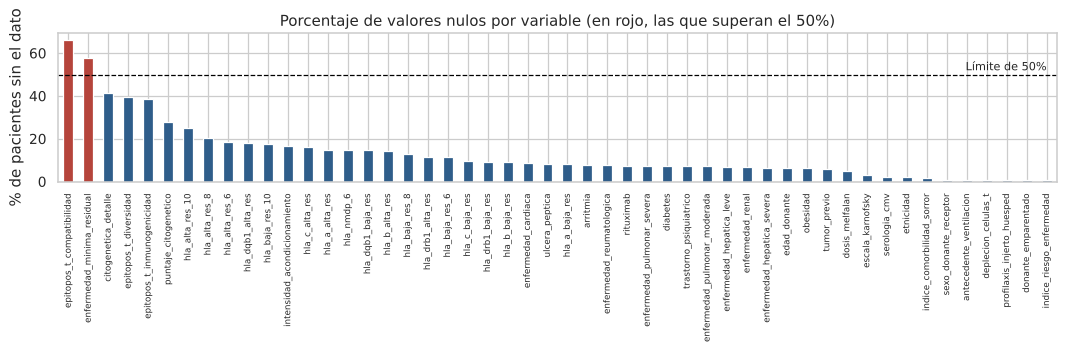

In [5]:
# Revisión general: duplicados, tipos y porcentaje de nulos por variable.
print("Filas duplicadas:", df_raw.duplicated().sum(), "| IDs repetidos:", df_raw["ID"].duplicated().sum())
print("Variables categóricas:", df_raw.select_dtypes(exclude="number").shape[1], "| numéricas:", df_raw.select_dtypes("number").shape[1])
nulos_pct = (df_raw.isna().mean() * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(12, 4))
nulos_pct[nulos_pct > 0].rename(index=NOMBRES).plot(kind="bar", ax=ax, color=[ROJO if v > 50 else AZUL for v in nulos_pct[nulos_pct > 0]])
ax.axhline(50, color="black", linestyle="--", linewidth=1)
ax.text(len(nulos_pct[nulos_pct > 0]) - 1, 52, "Límite de 50%", ha="right", fontsize=9)
ax.set_ylabel("% de pacientes sin el dato")
ax.set_title("Porcentaje de valores nulos por variable (en rojo, las que superan el 50%)")
ax.tick_params(axis="x", labelsize=7)
plt.tight_layout()

Análisis: no hay filas ni pacientes duplicados. Dos variables superan el 50% de nulos y se eliminan: la compatibilidad de epítopos de células T (66.0%) y la enfermedad mínima residual (57.6%). Les siguen la citogenética detallada (41.4%), los otros dos indicadores de epítopos (cerca de 39%) y las 17 variables HLA (entre 8% y 25%). Todas estas son genéticas. Entre las clínicas, la que más nulos tiene es la intensidad del acondicionamiento (16.6%).

## 3.2 Limpieza: de df_raw a df_clean

df_raw es el archivo tal como viene. df_clean es el resultado de tres reglas que se aplican fila por fila y no usan la variable objetivo, así que pueden hacerse antes de partir los datos sin fuga de información:

- Se eliminan las variables con más de 50% de nulos.
- En las variables genéticas, un nulo se marca como No aplica. Son la compatibilidad HLA (17 variables), la citogenética (2) y los epítopos de células T (2). Si el dato no está, lo más probable es que la prueba no se hizo o no correspondía al caso, así que llenarlo con un promedio inventaría un resultado genético.
- Se crean cinco variables nuevas: diferencia de edad entre donante y paciente, si el paciente es pediátrico, número de comorbilidades, si recibió irradiación corporal total y el índice de riesgo de la enfermedad agrupado en cinco niveles.

Los nulos que quedan en las demás variables se llenan más adelante dentro del Pipeline, para que ese paso aprenda solo de df_train.

In [6]:
# Limpieza: de df_raw a df_clean. Todas las reglas se aplican fila por fila y ninguna usa la variable objetivo.
# 1. Se eliminan las variables con más de 50% de nulos.
# 2. En las variables genéticas (compatibilidad HLA, citogenética y epítopos de células T) un nulo se marca "No aplica":
#    lo más probable es que la prueba no se hizo o no correspondía, así que no tiene sentido llenarlo con un promedio.
# 3. Se crean variables nuevas a partir de las existentes.
COLUMNAS_ELIMINADAS = [NOMBRES[c] for c in df_raw.columns if df_raw[c].isna().mean() > 0.5]
VARIABLES_GENETICAS = sorted(v for v in [c for c in NOMBRES.values() if c.startswith(("hla_", "epitopos_t_"))]
                             + ["puntaje_citogenetico", "citogenetica_detalle"] if v not in COLUMNAS_ELIMINADAS)
COMORBILIDADES = ["trastorno_psiquiatrico", "diabetes", "arritmia", "enfermedad_renal", "enfermedad_pulmonar_severa",
                  "enfermedad_pulmonar_moderada", "enfermedad_hepatica_severa", "enfermedad_hepatica_leve", "obesidad",
                  "tumor_previo", "ulcera_peptica", "enfermedad_reumatologica", "enfermedad_cardiaca"]
GRUPO_RIESGO = {
    "Low": "Bajo", "Intermediate": "Intermedio", "Intermediate - TED AML case <missing cytogenetics": "Intermedio",
    "High": "Alto", "High - TED AML case <missing cytogenetics": "Alto", "Very high": "Muy alto",
    "N/A - non-malignant indication": "No aplica", "N/A - pediatric": "No aplica", "N/A - disease not classifiable": "No aplica",
    "TBD cytogenetics": "Pendiente", "Missing disease status": "Pendiente",
}

def limpiar_datos(df, columnas_eliminadas, variables_geneticas):
    df = df.rename(columns=NOMBRES).drop(columns=columnas_eliminadas, errors="ignore")
    for c in variables_geneticas:
        if c in df.columns:
            texto = df[c].map(lambda v: f"{v:g}" if isinstance(v, (int, float)) and not pd.isna(v) else v)
            df[c] = texto.fillna("No aplica").astype(str)
    df["dif_edad_donante"] = df["edad_donante"] - df["edad_paciente"]
    df["es_pediatrico"] = (df["edad_paciente"] < 18).astype(int)
    df["n_comorbilidades"] = (df[COMORBILIDADES] == "Yes").sum(axis=1)
    df["recibio_irradiacion"] = (df["irradiacion_corporal_total"] != "No TBI").astype(int)
    df["grupo_riesgo_enfermedad"] = df["indice_riesgo_enfermedad"].map(GRUPO_RIESGO).fillna(df["indice_riesgo_enfermedad"])
    return df.drop(columns=["indice_riesgo_enfermedad"])

df_clean = limpiar_datos(df_raw, COLUMNAS_ELIMINADAS, VARIABLES_GENETICAS)
print("Variables eliminadas por superar 50% de nulos:", COLUMNAS_ELIMINADAS)
print("Variables genéticas con nulos marcados como No aplica:", len(VARIABLES_GENETICAS))
print("Variables nuevas: dif_edad_donante, es_pediatrico, n_comorbilidades, recibio_irradiacion, grupo_riesgo_enfermedad")
nulos_restantes = (df_clean.isna().mean() * 100).round(1)
print(f"Columnas: {df_raw.shape[1]} en df_raw y {df_clean.shape[1]} en df_clean | variables que aún tienen nulos: {(nulos_restantes > 0).sum()}")
(df_clean[VARIABLES_GENETICAS] == "No aplica").mean().mul(100).round(1).sort_values(ascending=False).rename("% marcado como No aplica").to_frame()

Variables eliminadas por superar 50% de nulos: ['enfermedad_minima_residual', 'epitopos_t_compatibilidad']
Variables genéticas con nulos marcados como No aplica: 21
Variables nuevas: dif_edad_donante, es_pediatrico, n_comorbilidades, recibio_irradiacion, grupo_riesgo_enfermedad
Columnas: 60 en df_raw y 62 en df_clean | variables que aún tienen nulos: 28


,% marcado como No aplica
citogenetica_detalle,41.4
epitopos_t_diversidad,39.6
epitopos_t_inmunogenicidad,38.7
puntaje_citogenetico,28.0
hla_alta_res_10,24.9
hla_alta_res_8,20.2
hla_alta_res_6,18.3
hla_dqb1_alta_res,18.1
hla_baja_res_10,17.6
hla_c_alta_res,16.0


Análisis: df_clean conserva 62 columnas (60 originales, menos 2 eliminadas, más 5 nuevas, menos el índice de riesgo original, que queda reemplazado por su versión agrupada). Las 21 variables genéticas que siguen en el dataset ya no tienen nulos: cuando el dato no estaba, ahora dicen No aplica, entre 8% y 41% de los pacientes según la variable. Quedan 28 variables con nulos, casi todas con menos de 10%, que se imputan dentro del Pipeline.

# 4. Variable objetivo: de tiempo hasta el evento a clasificación

La pregunta original es de supervivencia: cuántos meses pasan hasta el evento, una variable continua parecida a una regresión. Ese planteamiento tiene un problema: a muchos pacientes se les dejó de observar sin haber tenido el evento (censura), así que no se conoce su tiempo real. Se convierte en una clasificación con una pregunta concreta: ¿el paciente tendrá un evento en los primeros 12 meses, sí o no?

Tres razones lo justifican. La decisión clínica es binaria (seguimiento intensivo o habitual). Casi todos los eventos ocurren en el primer año, como muestra la curva siguiente. Y la censura se resuelve de forma limpia: solo se excluyen los pacientes sin evento que salieron del seguimiento antes de cumplir el año.

Pacientes con evento: 15,532 | mediana de meses hasta el evento: 5.8 | eventos dentro de 12 meses: 96.8%


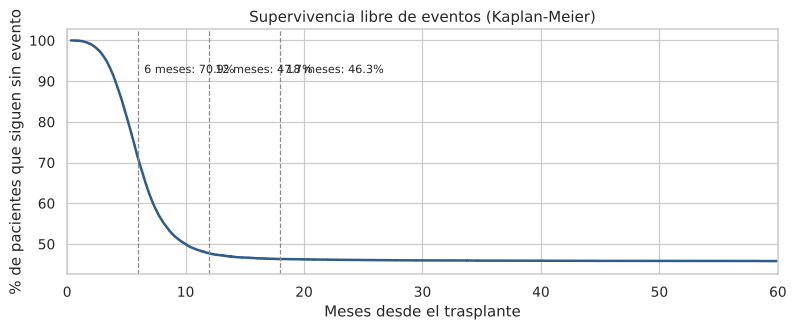

In [7]:
# Curva de Kaplan-Meier: probabilidad de seguir sin evento a lo largo del tiempo, teniendo en cuenta la censura.
def kaplan_meier(tiempo, evento):
    t, e = np.asarray(tiempo), np.asarray(evento)
    tiempos = np.unique(t[e == 1])
    en_riesgo = np.array([(t >= ti).sum() for ti in tiempos])
    eventos = np.array([((t == ti) & (e == 1)).sum() for ti in tiempos])
    return tiempos, np.cumprod(1 - eventos / en_riesgo)

tiempos, superv = kaplan_meier(df_clean["meses_hasta_evento"], df_clean["evento"])
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.step(tiempos, superv * 100, where="post", color=AZUL, linewidth=2)
for h in (6, 12, 18):
    ax.axvline(h, color=GRIS, linestyle="--", linewidth=1)
    ax.text(h + 0.5, 92, f"{h} meses: {superv[tiempos <= h][-1]:.1%}", fontsize=9)
ax.set_xlim(0, 60)
ax.set_xlabel("Meses desde el trasplante")
ax.set_ylabel("% de pacientes que siguen sin evento")
ax.set_title("Supervivencia libre de eventos (Kaplan-Meier)")
plt.tight_layout()
con_evento = df_clean.loc[df_clean["evento"] == 1, "meses_hasta_evento"]
print(f"Pacientes con evento: {len(con_evento):,} | mediana de meses hasta el evento: {con_evento.median():.1f} | eventos dentro de 12 meses: {(con_evento <= 12).mean():.1%}")

Análisis: la curva cae rápido durante el primer año. A los 6 meses sigue sin evento el 70.9% de los pacientes, a los 12 meses el 47.7% y a los 18 meses el 46.3%, es decir, entre el mes 12 y el 18 casi no pasa nada. De los 15,532 pacientes que tuvieron el evento, el 96.8% lo tuvo dentro de los primeros 12 meses, con una mediana de 5.8 meses. Esto respalda usar 12 meses como horizonte.

In [8]:
# Variable objetivo: evento adverso en los primeros 12 meses. Se excluyen los pacientes sin evento que dejaron
# de ser observados antes de los 12 meses, porque no se sabe qué les pasó al cumplir el año.
HORIZONTE = 12
def construir_objetivo(df, h):
    utiles = ~((df["evento"] == 0) & (df["meses_hasta_evento"] < h))
    df_salida = df[utiles].copy()
    df_salida["evento_12m"] = ((df_salida["evento"] == 1) & (df_salida["meses_hasta_evento"] <= h)).astype(int)
    return df_salida

df_model = construir_objetivo(df_clean, HORIZONTE)
COLUMNAS_PROTEGIDAS = ["grupo_racial", "etnicidad"]
COLUMNAS_NO_PREDICTORAS = ["id", "evento", "meses_hasta_evento", "evento_12m"] + COLUMNAS_PROTEGIDAS
COLUMNAS_ENTRADA = [c for c in df_model.columns if c not in COLUMNAS_NO_PREDICTORAS]
print(f"df_model: {len(df_model):,} pacientes ({len(df_clean) - len(df_model)} excluidos por censura antes de 12 meses)")
print(f"Con evento en 12 meses: {df_model['evento_12m'].mean():.1%} | sin evento: {1 - df_model['evento_12m'].mean():.1%}")
print("Predictores:", len(COLUMNAS_ENTRADA))

df_model: 28,562 pacientes (238 excluidos por censura antes de 12 meses)
Con evento en 12 meses: 52.6% | sin evento: 47.4%
Predictores: 57


Análisis: solo 238 pacientes (0.8%) se excluyen por haber salido del seguimiento antes del año sin evento. df_model queda con 28,562 pacientes y 57 predictores, con 52.6% de pacientes con evento en 12 meses y 47.4% sin evento: las clases están casi balanceadas.

Partición de df_model en df_train (70%), df_val (15%) y df_test (15%), antes de cualquier paso que aprenda de los datos. El test.csv de la competencia no se usa porque solo trae 3 pacientes y no incluye el resultado; Kaggle guarda las respuestas en privado. El grupo racial y la etnicidad no se usan como predictores: se reservan para revisar que el modelo funcione igual de bien en todos los grupos.

In [9]:
# Partición 70 / 15 / 15 antes de cualquier transformación que aprenda de los datos, estratificada por objetivo y grupo racial.
estrato = df_model["evento_12m"].astype(str) + "_" + df_model["grupo_racial"]
df_temp, df_test = train_test_split(df_model, test_size=0.15, stratify=estrato, random_state=SEMILLA)
df_train, df_val = train_test_split(df_temp, test_size=0.15 / 0.85, stratify=estrato.loc[df_temp.index], random_state=SEMILLA)
X_train, X_val, X_test = df_train[COLUMNAS_ENTRADA], df_val[COLUMNAS_ENTRADA], df_test[COLUMNAS_ENTRADA]
y_train, y_val, y_test = df_train["evento_12m"], df_val["evento_12m"], df_test["evento_12m"]
pd.DataFrame({"pacientes": [len(df_train), len(df_val), len(df_test)],
              "% con evento en 12 meses": [round(y.mean() * 100, 2) for y in (y_train, y_val, y_test)]},
             index=["df_train", "df_val", "df_test"])

,pacientes,% con evento en 12 meses
df_train,19992,52.62
df_val,4285,52.65
df_test,4285,52.65


Análisis: los tres conjuntos tienen la misma proporción de eventos (52.6%) gracias a la estratificación, que también mantiene la mezcla de grupos raciales. df_test (4,285 pacientes) no se vuelve a tocar hasta la sección 10.

# 5. Análisis exploratorio

Todo el análisis usa solo df_train.

## 5.1 Edad del paciente y del donante

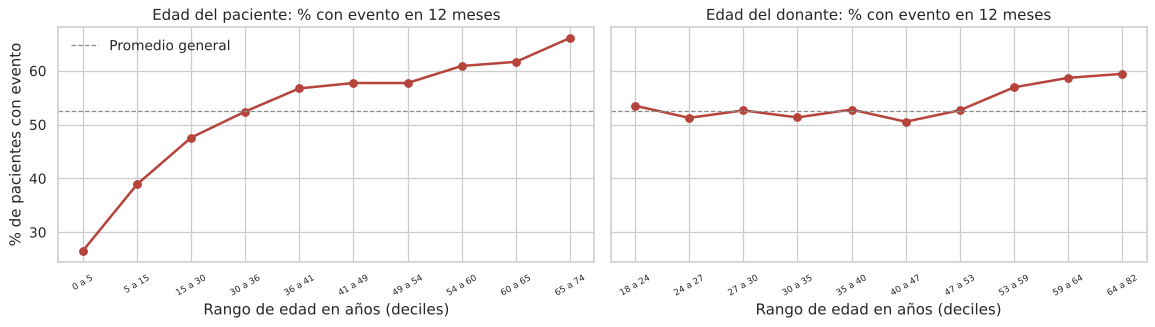

In [10]:
# Porcentaje de pacientes con evento en 12 meses por deciles de edad del paciente y del donante (solo df_train).
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, col, titulo in zip(axes, ["edad_paciente", "edad_donante"], ["Edad del paciente", "Edad del donante"]):
    decil = pd.qcut(df_train[col], 10, duplicates="drop")
    tasa = y_train.groupby(decil.values, observed=True).mean()
    ax.plot(range(len(tasa)), tasa.values * 100, marker="o", color=ROJO, linewidth=2)
    ax.set_xticks(range(len(tasa)))
    ax.set_xticklabels([f"{iv.left:.0f} a {iv.right:.0f}" for iv in tasa.index], fontsize=7, rotation=30)
    ax.axhline(y_train.mean() * 100, color=GRIS, linestyle="--", linewidth=1, label="Promedio general")
    ax.set_title(f"{titulo}: % con evento en 12 meses")
    ax.set_xlabel("Rango de edad en años (deciles)")
axes[0].set_ylabel("% de pacientes con evento")
axes[0].legend(frameon=False)
plt.tight_layout()

Análisis: la edad del paciente es uno de los factores más claros. En los niños de 0 a 5 años solo el 26% tiene un evento en el primer año, en el rango de 30 a 36 años ya está en el promedio (52%) y en los mayores de 65 llega a 66%. La edad del donante pesa mucho menos: la curva se mantiene alrededor del promedio hasta los 53 años y solo sube a 57% a 59% con donantes mayores. Por eso se creó la variable de diferencia de edad entre donante y paciente.

## 5.2 Variables clínicas principales

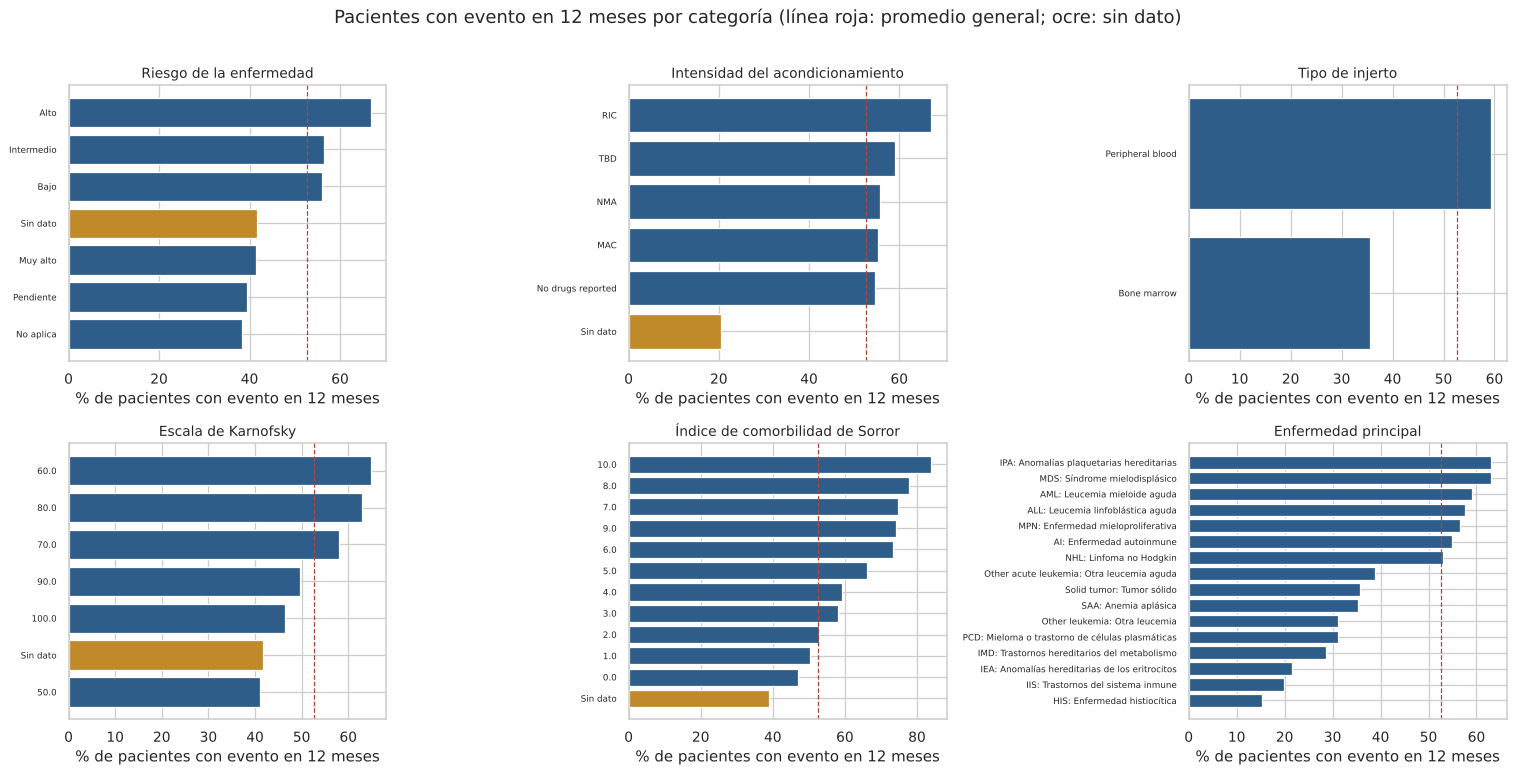

In [11]:
# Porcentaje con evento en 12 meses según la categoría de seis variables clínicas (categorías con 50 o más pacientes).
paneles = {"grupo_riesgo_enfermedad": "Riesgo de la enfermedad", "intensidad_acondicionamiento": "Intensidad del acondicionamiento",
           "tipo_injerto": "Tipo de injerto", "escala_karnofsky": "Escala de Karnofsky",
           "indice_comorbilidad_sorror": "Índice de comorbilidad de Sorror", "enfermedad_principal": "Enfermedad principal"}
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
for ax, (col, titulo) in zip(axes.ravel(), paneles.items()):
    serie = df_train[col].astype(object).where(df_train[col].notna(), "Sin dato").astype(str)
    if col == "enfermedad_principal":
        serie = serie.map(etiqueta_enfermedad)
    resumen = y_train.groupby(serie.values).agg(["mean", "size"])
    resumen = resumen[resumen["size"] >= 50].sort_values("mean")
    ax.barh(resumen.index, resumen["mean"] * 100, color=[OCRE if i == "Sin dato" else AZUL for i in resumen.index])
    ax.axvline(y_train.mean() * 100, color=ROJO, linestyle="--", linewidth=1)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel("% de pacientes con evento en 12 meses")
    ax.tick_params(axis="y", labelsize=7)
plt.suptitle("Pacientes con evento en 12 meses por categoría (línea roja: promedio general; ocre: sin dato)", y=1.01)
plt.tight_layout()

Análisis: todas las variables separan bien el riesgo y en la dirección esperada. Un índice de riesgo alto lleva al 66% con evento, el acondicionamiento de intensidad reducida (RIC) al 67% frente a 55% del intenso (MAC), la sangre periférica al 60% frente a 35% de la médula ósea, y el índice de Sorror sube de forma casi continua de 47% con 0 puntos a 84% con 10. En la escala de Karnofsky los pacientes con 60 puntos tienen 65% de eventos y los de 100, 46%. Por enfermedad, el riesgo va de 15% en la enfermedad histiocítica a más de 60% en el síndrome mielodisplásico.

Lo más llamativo son las barras ocre: los pacientes sin dato tienen mucho menos riesgo que cualquier categoría real. Sin dato de intensidad, solo el 20% tiene evento. Eso no puede ser un efecto clínico del dato vacío, así que se investiga en las secciones 5.4 y 5.5.

## 5.3 Compatibilidad HLA y PCA

HLA son los antígenos leucocitarios humanos: marcadores genéticos con los que el sistema inmune distingue lo propio de lo ajeno. Entre más se parezcan los del donante y los del paciente, menor es el riesgo de rechazo. El dataset trae 17 variables que cuentan coincidencias en distintos genes y con dos niveles de detalle (baja y alta resolución).

Correlación media entre pares de variables HLA: 0.763 | mínima: 0.494
Pacientes con hla_alta_res_8 en No aplica: 20.1% | % con evento: 51.7% frente a 52.9% con el dato


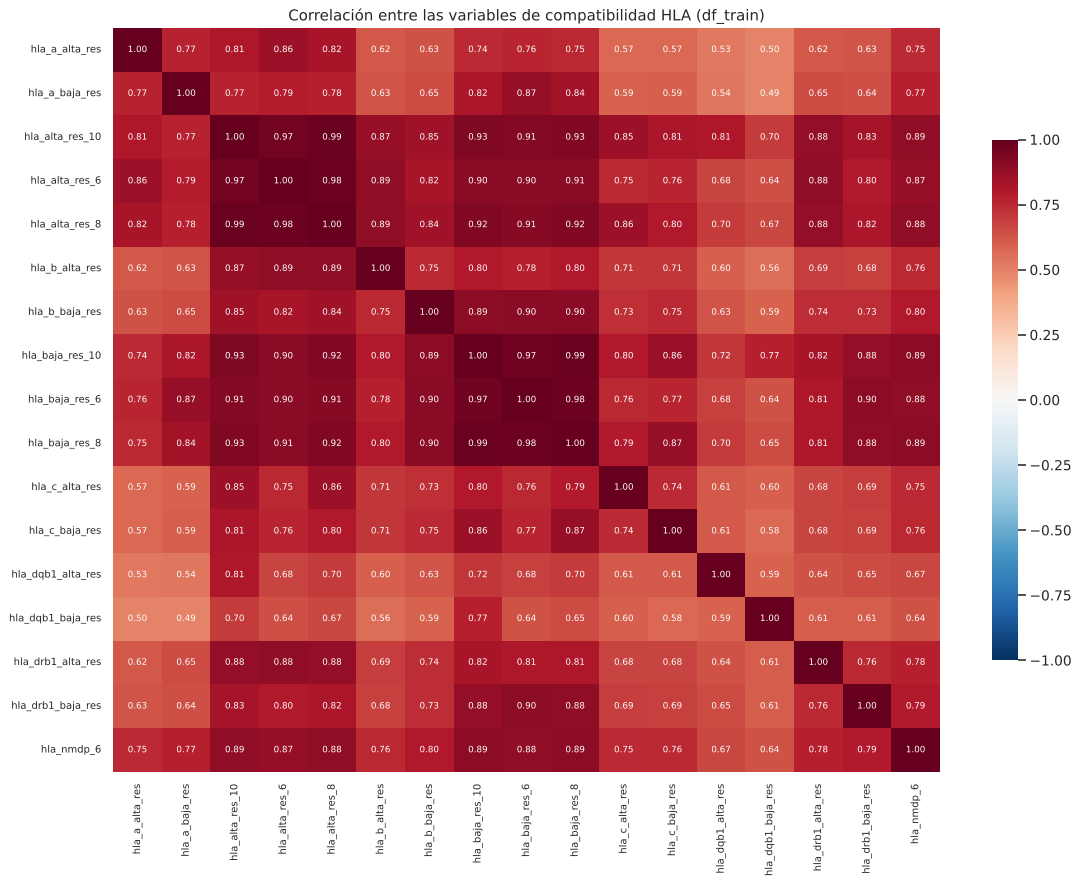

In [12]:
# Las 17 variables HLA miden qué tan compatibles son paciente y donante. Correlación entre ellas con su valor numérico.
COLUMNAS_HLA = sorted([c for c in df_clean.columns if c.startswith("hla_")])
hla_numerico = df_train[COLUMNAS_HLA].apply(pd.to_numeric, errors="coerce")
corr_hla = hla_numerico.corr()
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr_hla, annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.7})
ax.tick_params(labelsize=8)
ax.set_title("Correlación entre las variables de compatibilidad HLA (df_train)")
plt.tight_layout()
triu = corr_hla.where(np.triu(np.ones(corr_hla.shape, dtype=bool), k=1)).stack()
print(f"Correlación media entre pares de variables HLA: {triu.mean():.3f} | mínima: {triu.min():.3f}")
sin_hla = df_train["hla_alta_res_8"] == "No aplica"
print(f"Pacientes con hla_alta_res_8 en No aplica: {sin_hla.mean():.1%} | % con evento: {y_train[sin_hla].mean():.1%} "
      f"frente a {y_train[~sin_hla].mean():.1%} con el dato")

Análisis: las variables HLA son casi copias unas de otras, con una correlación media de 0.763 entre pares y ninguna por debajo de 0.49. Las que resumen varios genes (por ejemplo hla_alta_res_8 y hla_alta_res_10) llegan a 0.99. Tener 17 versiones de la misma información infla el número de columnas sin aportar mucho, lo que justifica aplicar PCA a este bloque. El 20.1% de los pacientes no tiene el dato de hla_alta_res_8 (ahora No aplica) y su porcentaje con evento (51.7%) es casi igual al de quienes sí lo tienen (52.9%).

Columnas One-Hot del bloque HLA: 88 | primer componente: 41.6% | componentes para el 95%: 28


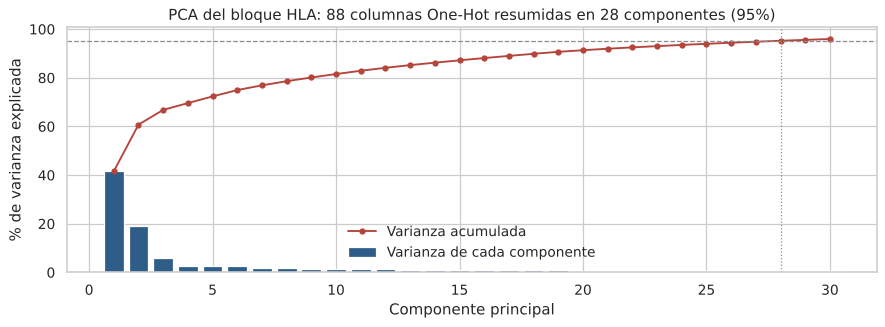

In [13]:
# PCA sobre el bloque HLA codificado con One-Hot (cada valor, incluido No aplica, es una columna).
pipelinePcaHLA = Pipeline([("oneHotEncoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False)),
                           ("pca", PCA(random_state=SEMILLA))]).fit(df_train[COLUMNAS_HLA])
varianza = pipelinePcaHLA.named_steps["pca"].explained_variance_ratio_
varianza_acum = np.cumsum(varianza)
N_COMPONENTES_HLA = int(np.searchsorted(varianza_acum, 0.95) + 1)
n_onehot = len(varianza)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(range(1, 31), varianza[:30] * 100, color=AZUL, label="Varianza de cada componente")
ax.plot(range(1, 31), varianza_acum[:30] * 100, color=ROJO, marker="o", markersize=4, label="Varianza acumulada")
ax.axhline(95, color=GRIS, linestyle="--", linewidth=1)
ax.axvline(N_COMPONENTES_HLA, color=GRIS, linestyle=":", linewidth=1)
ax.set_xlabel("Componente principal")
ax.set_ylabel("% de varianza explicada")
ax.set_title(f"PCA del bloque HLA: {n_onehot} columnas One-Hot resumidas en {N_COMPONENTES_HLA} componentes (95%)")
ax.legend(frameon=False)
plt.tight_layout()
print(f"Columnas One-Hot del bloque HLA: {n_onehot} | primer componente: {varianza[0]:.1%} | componentes para el 95%: {N_COMPONENTES_HLA}")

Análisis: al codificar con One-Hot, el bloque HLA pasa a 88 columnas. El primer componente ya explica el 41.6% de la varianza y el segundo lleva el acumulado a cerca del 60%; con 28 componentes se conserva el 95%. Se reduce el bloque a menos de un tercio de sus columnas sin perder casi información.

## 5.4 Quién tiene datos vacíos

Después de la limpieza, las variables genéticas ya no tienen nulos. Esta sección revisa las demás: cuántas variables vacías tiene cada paciente y en qué segmentos se concentran.

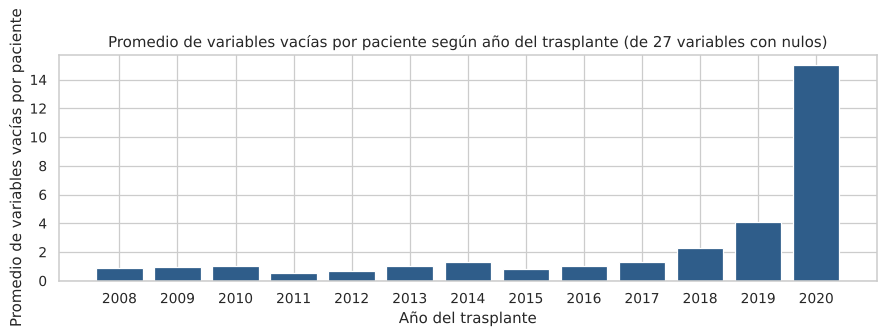

,pacientes,variables_vacias_promedio,pct_sin_intensidad
grupo_edad,,,
Adulto,15329,1.34,7.4
Pediátrico,4663,1.69,47.9


In [14]:
# ¿Quién tiene datos vacíos? Se cuentan las variables no genéticas que siguen vacías en cada paciente.
COLUMNAS_CON_NULOS = [c for c in COLUMNAS_ENTRADA if df_train[c].isna().any()]
df_eda = df_train.copy()
df_eda["n_vacias"] = df_eda[COLUMNAS_CON_NULOS].isna().sum(axis=1)
df_eda["sin_intensidad"] = df_eda["intensidad_acondicionamiento"].isna()
df_eda["grupo_edad"] = np.where(df_eda["es_pediatrico"] == 1, "Pediátrico", "Adulto")
por_anio = df_eda.groupby("anio_trasplante")["n_vacias"].mean()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(por_anio.index.astype(str), por_anio.values, color=AZUL)
ax.set_xlabel("Año del trasplante")
ax.set_ylabel("Promedio de variables vacías por paciente")
ax.set_title(f"Promedio de variables vacías por paciente según año del trasplante (de {len(COLUMNAS_CON_NULOS)} variables con nulos)")
plt.tight_layout()
df_eda.groupby("grupo_edad").agg(pacientes=("id", "size"), variables_vacias_promedio=("n_vacias", "mean"),
                                 pct_sin_intensidad=("sin_intensidad", "mean")).assign(pct_sin_intensidad=lambda d: (d["pct_sin_intensidad"] * 100).round(1)).round(2)

Análisis: entre 2008 y 2017 cada paciente tiene en promedio alrededor de una variable vacía, de las 27 que todavía pueden tener nulos. A partir de 2018 el número sube y en 2020 llega a 15 por paciente. Los vacíos se concentran en los registros más recientes, lo que apunta a formularios que todavía no se habían completado cuando se armó el registro. La tabla muestra además que a los pacientes pediátricos les falta la intensidad del acondicionamiento en el 47.9% de los casos, frente a 7.4% en los adultos.

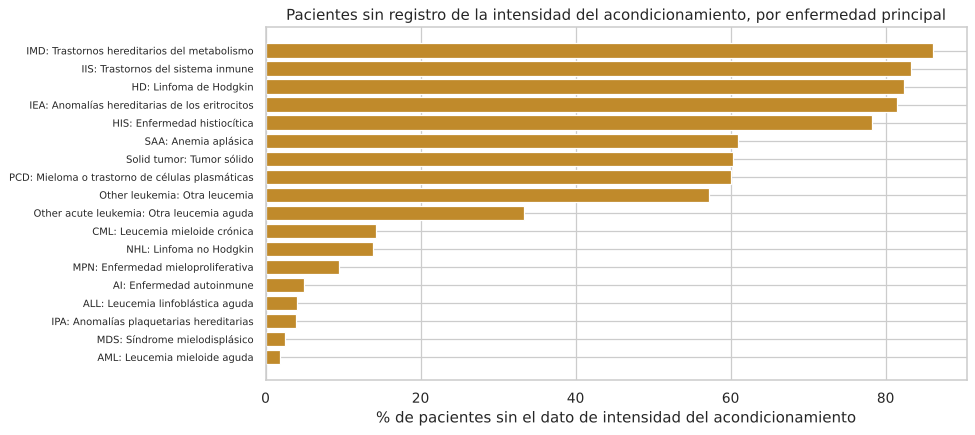

In [15]:
# La variable no genética con más nulos es la intensidad del acondicionamiento (la quimioterapia o radiación previa al trasplante).
# Se mide qué porcentaje de pacientes de cada enfermedad no tiene ese dato registrado.
por_enf = df_eda.groupby("enfermedad_principal")["sin_intensidad"].mean().sort_values() * 100
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh([etiqueta_enfermedad(c) for c in por_enf.index], por_enf.values, color=OCRE)
ax.set_xlabel("% de pacientes sin el dato de intensidad del acondicionamiento")
ax.set_title("Pacientes sin registro de la intensidad del acondicionamiento, por enfermedad principal")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()

Análisis: la falta del dato de intensidad no es aleatoria, depende de la enfermedad. Les falta al 78% o más de los pacientes con enfermedades hereditarias o no malignas (trastornos del metabolismo, del sistema inmune, de los eritrocitos y la enfermedad histiocítica) y también al 82% de los pocos casos de linfoma de Hodgkin. En cambio, en las leucemias agudas y el síndrome mielodisplásico casi siempre está (menos de 5% sin dato). Estas son, además, las enfermedades de menor riesgo en la sección 5.2.

## 5.5 Datos vacíos y seguimiento en el tiempo

In [16]:
# ¿Los vacíos se deben a pacientes que dejan de asistir con el tiempo? Se compara el seguimiento de los pacientes
# sin evento según cuántas variables tienen vacías, y el % con evento con y sin el dato de intensidad.
df_censurados = df_eda[df_eda["evento"] == 0]
seguimiento = df_censurados.groupby(pd.cut(df_censurados["n_vacias"], [-1, 0, 2, 5, 60], labels=["0", "1 a 2", "3 a 5", "6 o más"]),
                                    observed=True)["meses_hasta_evento"].agg(["size", "median"]).rename(
    columns={"size": "pacientes sin evento", "median": "mediana de meses de seguimiento"})
display(seguimiento.round(1))
tabla_intensidad = df_eda.groupby(["grupo_edad", "sin_intensidad"])["evento_12m"].agg(["size", "mean"])
tabla_intensidad.columns = ["pacientes", "% con evento en 12 meses"]
tabla_intensidad["% con evento en 12 meses"] = (tabla_intensidad["% con evento en 12 meses"] * 100).round(1)
tabla_intensidad

,pacientes sin evento,mediana de meses de seguimiento
n_vacias,,
0,4337,39.5
1 a 2,3189,37.8
3 a 5,931,35.9
6 o más,658,27.3


pacientes  % con evento en 12 meses
grupo_edad sin_intensidad                                     
Adulto     False               14198                      61.0
           True                 1131                      23.6
Pediátrico False                2428                      48.4
           True                 2235                      18.9

Análisis: los vacíos no vienen de pacientes que dejan de asistir. Los pacientes sin evento tienen un seguimiento de 36 a 40 meses en mediana, tengan 0 o 5 variables vacías. El grupo con 6 o más vacías tiene menos seguimiento (27.3 meses), lo que coincide con la gráfica anterior: los trasplantes de 2019 y 2020 son los que más vacíos tienen y también los que llevan menos tiempo de observación.

El efecto sobre el riesgo es grande: en los adultos, el 61.0% de quienes tienen el dato de intensidad tuvo un evento, frente a 23.6% de quienes no lo tienen. En los niños, 48.4% frente a 18.9%. El vacío funciona como una señal de que el paciente pertenece a un grupo de bajo riesgo, no como un dato clínico.

## 5.6 Conclusiones del análisis exploratorio

- El riesgo depende sobre todo de la edad, la comorbilidad (Sorror), el estado funcional (Karnofsky), el tipo de injerto, la intensidad del acondicionamiento y la enfermedad.
- Las 17 variables HLA son muy redundantes y se pueden resumir con PCA.
- Los datos vacíos tienen un patrón claro: se concentran en pacientes pediátricos, en enfermedades hereditarias o no malignas y en los trasplantes de 2018 a 2020. No se deben a pacientes que abandonan el seguimiento.
- Un vacío se asocia a mucho menos riesgo. Si el modelo aprende eso, le bajaría el riesgo a cualquier paciente con el formulario incompleto. La sección 6 compara dos formas de imputar para evitarlo.

# 6. Preparación de datos: Pipeline, imputación y reducción de dimensión

Todo el preprocesamiento se arma con clases estándar de scikit-learn dentro de un Pipeline, de modo que en la validación cruzada cada paso aprende solo de los pliegues de entrenamiento:

- Bloque HLA: OneHotEncoder (cada valor, incluido No aplica, es una columna) y PCA.
- Numéricas: SimpleImputer con la mediana y StandardScaler. El escalado es necesario para LogisticRegression, KNN y PCA; a los modelos de árboles no les afecta.
- Categóricas: SimpleImputer y OneHotEncoder, agrupando las categorías con menos de 20 pacientes.

In [17]:
# Preprocesamiento con clases estándar de scikit-learn dentro de un Pipeline, así cada paso aprende solo de df_train.
# HLA: One-Hot y PCA. Numéricas: mediana y escalado. Categóricas: valor más frecuente y One-Hot.
COLUMNAS_CATEGORICAS = [c for c in COLUMNAS_ENTRADA if c not in COLUMNAS_HLA and not pd.api.types.is_numeric_dtype(df_model[c])]
COLUMNAS_NUMERICAS = [c for c in COLUMNAS_ENTRADA if c not in COLUMNAS_HLA + COLUMNAS_CATEGORICAS]

def crear_pipeline(estimador, imputacion_categorica="most_frequent", pca_hla=True, pca_global=None):
    pasos_hla = [("oneHotEncoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False))]
    if pca_hla:
        pasos_hla.append(("pca", PCA(n_components=N_COMPONENTES_HLA, random_state=SEMILLA)))
    columnTransformer = ColumnTransformer([
        ("hla", Pipeline(pasos_hla), COLUMNAS_HLA),
        ("num", Pipeline([("simpleImputer", SimpleImputer(strategy="median")), ("standardScaler", StandardScaler())]), COLUMNAS_NUMERICAS),
        ("cat", Pipeline([("simpleImputer", SimpleImputer(strategy=imputacion_categorica, fill_value="No informado")),
                          ("oneHotEncoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False))]),
         COLUMNAS_CATEGORICAS),
    ])
    pasos = [("columnTransformer", columnTransformer)]
    if pca_global is not None:
        pasos.append(("pca", PCA(n_components=pca_global, random_state=SEMILLA)))
    pasos.append(("modelo", estimador))
    return Pipeline(pasos)

print(f"Predictores: {len(COLUMNAS_HLA)} HLA, {len(COLUMNAS_NUMERICAS)} numéricos y {len(COLUMNAS_CATEGORICAS)} categóricos")
print("Columnas que recibe el modelo:", crear_pipeline(LogisticRegression())[:-1].fit_transform(X_train).shape[1])
print("Pasos del Pipeline:", [nombre for nombre, _ in crear_pipeline(XGBClassifier()).steps])

Predictores: 17 HLA, 9 numéricos y 31 categóricos
Columnas que recibe el modelo: 181
Pasos del Pipeline: ['columnTransformer', 'modelo']


Análisis: el Pipeline recibe 57 predictores (17 HLA, 9 numéricos y 31 categóricos) y los convierte en 181 columnas: 28 componentes del bloque HLA, 9 numéricas escaladas y 144 columnas One-Hot de las categóricas. Como todo vive dentro del mismo objeto, el modelo exportado repite exactamente estos pasos con un paciente nuevo.

Experimento de imputación. En el análisis exploratorio se vio que un dato vacío se asocia a mucho menos riesgo. Si el modelo aprende eso, le bajaría el riesgo a cualquier paciente con el formulario incompleto. Se comparan dos estrategias de SimpleImputer para las categóricas: constant, que crea la categoría No informado, y most_frequent, que pone el valor más común.

In [18]:
# Dos formas de llenar los nulos de las categóricas no genéticas, comparadas en df_val:
# most_frequent (valor más común) y constant (una categoría "No informado").
# Cambio de riesgo con vacíos: diferencia en el riesgo promedio cuando, a pacientes completos de df_val, se les borran
# la intensidad del acondicionamiento, la escala de Karnofsky y el índice de Sorror.
X_val_completos = X_val[X_val[["intensidad_acondicionamiento", "escala_karnofsky", "indice_comorbilidad_sorror"]].notna().all(axis=1)]
X_val_borrados = X_val_completos.copy()
X_val_borrados["intensidad_acondicionamiento"] = pd.Series(np.nan, index=X_val_borrados.index, dtype=object)
X_val_borrados[["escala_karnofsky", "indice_comorbilidad_sorror"]] = np.nan
filas = []
for nombre_modelo, estimador in [("LogisticRegression", LogisticRegression(max_iter=3000, C=0.1)),
                                 ("XGBClassifier", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, n_jobs=2, random_state=SEMILLA))]:
    for estrategia in ["constant", "most_frequent"]:
        pipeline = crear_pipeline(estimador, imputacion_categorica=estrategia).fit(X_train, y_train)
        cambio = pipeline.predict_proba(X_val_borrados)[:, 1].mean() - pipeline.predict_proba(X_val_completos)[:, 1].mean()
        filas.append({"modelo": nombre_modelo, "SimpleImputer": estrategia,
                      "AUC en df_val": roc_auc_score(y_val, pipeline.predict_proba(X_val)[:, 1]),
                      "cambio de riesgo con vacíos (puntos %)": cambio * 100})
tabla_imputacion = pd.DataFrame(filas).set_index(["modelo", "SimpleImputer"]).round(4)
print(f"Pacientes completos de df_val usados para medir el cambio: {len(X_val_completos):,}")
tabla_imputacion

Pacientes completos de df_val usados para medir el cambio: 3,447


AUC en df_val  cambio de riesgo con vacíos (puntos %)
modelo             SimpleImputer                                                       
LogisticRegression constant              0.7397                                -21.7501
                   most_frequent         0.7369                                 -5.4370
XGBClassifier      constant              0.7412                                -31.8954
                   most_frequent         0.7378                                 -6.8380

Análisis: con la categoría No informado (constant) el modelo aprende que el vacío significa bajo riesgo. Al borrarle tres datos a 3,447 pacientes completos, su riesgo promedio cae 21.8 puntos con LogisticRegression y 31.9 con XGBClassifier. Con most_frequent la caída se reduce a 5.4 y 6.8 puntos, y el AUC solo baja 0.003 en ambos modelos.

Se elige most_frequent: cuesta muy poco en AUC y deja un modelo que no premia los formularios incompletos, que es lo que pasaría en la práctica con un paciente nuevo al que todavía le faltan datos.

Experimento de reducción de dimensión: se compara no usar PCA, usarlo solo en el bloque HLA y usarlo sobre todas las columnas.

In [19]:
# Reducción de dimensión con LogisticRegression en df_val: sin PCA, PCA solo en HLA y PCA sobre todas las columnas.
filas = []
for variante, kw in [("Sin PCA", dict(pca_hla=False)), (f"PCA solo en HLA ({N_COMPONENTES_HLA} componentes)", dict(pca_hla=True)),
                     ("PCA sobre todas las columnas (95% de varianza)", dict(pca_hla=True, pca_global=0.95))]:
    pipeline = crear_pipeline(LogisticRegression(max_iter=3000, C=0.1), **kw).fit(X_train, y_train)
    filas.append({"variante": variante, "columnas que recibe el modelo": pipeline[:-1].transform(X_val.head(1)).shape[1],
                  "AUC en df_val": roc_auc_score(y_val, pipeline.predict_proba(X_val)[:, 1])})
pd.DataFrame(filas).set_index("variante").round(4)

,columnas que recibe el modelo,AUC en df_val
variante,,
Sin PCA,241,0.7377
PCA solo en HLA (28 componentes),181,0.7369
PCA sobre todas las columnas (95% de varianza),72,0.7315


Análisis: aplicar PCA solo al bloque HLA reduce las columnas de 241 a 181 con una pérdida mínima de AUC (de 0.7377 a 0.7369). Aplicarlo sobre todas las columnas las baja a 72, pero el AUC cae a 0.7315, porque mezcla variables clínicas que sí aportan información distinta. Se usa PCA solo en el bloque HLA.

# 7. Balanceo de clases

In [20]:
# Balance de clases y dos estrategias de balanceo, entrenando con df_train y midiendo en df_val (umbral 0.5).
# Estrategia 1: pesos por clase con compute_sample_weight("balanced").
# Estrategia 2: submuestreo aleatorio de la clase mayoritaria de df_train.
print(f"Proporción en df_train: {y_train.mean():.1%} con evento y {1 - y_train.mean():.1%} sin evento")
clase_mayor = y_train.value_counts().idxmax()
df_train_submuestreo = pd.concat([df_train[y_train == clase_mayor].sample((y_train != clase_mayor).sum(), random_state=SEMILLA),
                                  df_train[y_train != clase_mayor]])
filas = []
for nombre_modelo, estimador in [("LogisticRegression", LogisticRegression(max_iter=3000, C=0.1)),
                                 ("XGBClassifier", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, n_jobs=2, random_state=SEMILLA))]:
    variantes = {
        "sin balanceo": crear_pipeline(clone(estimador)).fit(X_train, y_train),
        "pesos por clase": crear_pipeline(clone(estimador)).fit(X_train, y_train, modelo__sample_weight=compute_sample_weight("balanced", y_train)),
        "submuestreo": crear_pipeline(clone(estimador)).fit(df_train_submuestreo[COLUMNAS_ENTRADA], df_train_submuestreo["evento_12m"]),
    }
    for estrategia, pipeline in variantes.items():
        prob = pipeline.predict_proba(X_val)[:, 1]
        filas.append({"modelo": nombre_modelo, "estrategia": estrategia, "AUC": roc_auc_score(y_val, prob),
                      "F1 macro": f1_score(y_val, prob >= 0.5, average="macro"), "balanced accuracy": balanced_accuracy_score(y_val, prob >= 0.5),
                      "recall del evento": recall_score(y_val, prob >= 0.5)})
tabla_balanceo = pd.DataFrame(filas).set_index(["modelo", "estrategia"]).round(4)
# El balanceo solo cambia el punto de corte entre clases; ese efecto se logra también moviendo el umbral (sección 9).
# Por eso la decisión se toma con el AUC, que no depende del umbral: se balancea solo si mejora más de 0.005.
mejora_auc = tabla_balanceo["AUC"].unstack().pipe(lambda t: t.max(axis=1) - t["sin balanceo"])
mejora_bal = tabla_balanceo["balanced accuracy"].unstack().pipe(lambda t: t.max(axis=1) - t["sin balanceo"])
USAR_BALANCEO = bool((mejora_auc > 0.005).any())
print("Mayor mejora en AUC frente a no balancear:", mejora_auc.round(4).to_dict())
print("Mayor mejora en balanced accuracy con umbral 0.5:", mejora_bal.round(4).to_dict())
print("Decisión:", "usar balanceo" if USAR_BALANCEO else "no usar balanceador")
tabla_balanceo

Proporción en df_train: 52.6% con evento y 47.4% sin evento
Mayor mejora en AUC frente a no balancear: {'LogisticRegression': 0.0004, 'XGBClassifier': 0.0}
Mayor mejora en balanced accuracy con umbral 0.5: {'LogisticRegression': 0.0049, 'XGBClassifier': 0.0053}
Decisión: no usar balanceador


AUC  ...  recall del evento
modelo             estrategia               ...                   
LogisticRegression sin balanceo     0.7369  ...             0.7394
                   pesos por clase  0.7368  ...             0.6955
                   submuestreo      0.7373  ...             0.6990
XGBClassifier      sin balanceo     0.7378  ...             0.7482
                   pesos por clase  0.7368  ...             0.7039
                   submuestreo      0.7375  ...             0.7057

[6 rows x 4 columns]

Análisis: con 52.6% y 47.4%, las clases están prácticamente balanceadas. Ninguna de las dos estrategias mejora el AUC (la mayor mejora es 0.0004). Sí suben un poco el balanced accuracy con umbral 0.5 (0.005), pero a costa de detectar menos eventos (el recall de XGBClassifier baja de 0.748 a cerca de 0.705). Ese mismo ajuste se logra eligiendo el umbral de alerta en la sección 9, sin cambiar los datos de entrenamiento. Por eso no se usa balanceador.

# 8. Comparación de modelos

Seis modelos con el mismo Pipeline de preprocesamiento: LogisticRegression, KNeighborsClassifier, RandomForestClassifier, AdaBoostClassifier, HistGradientBoostingClassifier (la implementación de Gradient Boosting de scikit-learn) y XGBClassifier. Para KNN se agrega un PCA global porque las distancias pierden sentido con más de 150 columnas.

In [21]:
# Seis modelos con el mismo preprocesamiento, evaluados con StratifiedKFold de 10 pliegues sobre df_train.
modelos = {
    "LogisticRegression": (LogisticRegression(max_iter=3000, C=0.1), None),
    "KNeighborsClassifier": (KNeighborsClassifier(n_neighbors=75, weights="distance"), 0.90),
    "RandomForestClassifier": (RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=2, random_state=SEMILLA), None),
    "AdaBoostClassifier": (AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=SEMILLA), None),
    "HistGradientBoostingClassifier": (HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=SEMILLA), None),
    "XGBClassifier": (XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.9, colsample_bytree=0.8,
                                    n_jobs=2, random_state=SEMILLA), None),
}
stratifiedKFold10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMILLA)
metricas = {"auc": "roc_auc", "ap": "average_precision", "f1": "f1_macro", "bal": "balanced_accuracy"}
resultados_cv = {nombre: cross_validate(crear_pipeline(estimador, pca_global=pca), X_train, y_train, cv=stratifiedKFold10, scoring=metricas)
                 for nombre, (estimador, pca) in modelos.items()}
tabla_cv = pd.DataFrame({n: {"AUC (media)": r["test_auc"].mean(), "AUC (desv.)": r["test_auc"].std(),
                             "average precision": r["test_ap"].mean(), "F1 macro": r["test_f1"].mean(),
                             "balanced accuracy": r["test_bal"].mean(), "segundos por ajuste": r["fit_time"].mean()}
                         for n, r in resultados_cv.items()}).T.sort_values("AUC (media)", ascending=False)
tabla_cv.round(4)

,AUC (media),AUC (desv.),average precision,F1 macro,balanced accuracy,segundos por ajuste
XGBClassifier,0.7342,0.0060,0.7394,0.6700,0.6702,1.6132
LogisticRegression,0.7314,0.0073,0.7373,0.6660,0.6660,0.7481
HistGradientBoostingClassifier,0.7279,0.0073,0.7322,0.6653,0.6655,2.2960
AdaBoostClassifier,0.7265,0.0078,0.7348,0.6610,0.6616,10.5922
RandomForestClassifier,0.7183,0.0101,0.7236,0.6548,0.6559,4.9086
KNeighborsClassifier,0.6952,0.0104,0.6965,0.6424,0.6429,0.5224


Análisis: XGBClassifier obtiene el mejor AUC promedio (0.7342) y la menor variación entre pliegues (0.0060), seguido muy de cerca por LogisticRegression (0.7314). HistGradientBoosting y AdaBoost quedan un poco más abajo, RandomForest pierde algo de capacidad y KNN es el más débil (0.6952), algo esperable con tantas columnas categóricas. XGBClassifier entrena en menos de 2 segundos por ajuste.

Prueba de Wilcoxon XGBClassifier vs LogisticRegression: diferencia media de AUC 0.0028, p-valor 0.0039
Modelo elegido: XGBClassifier


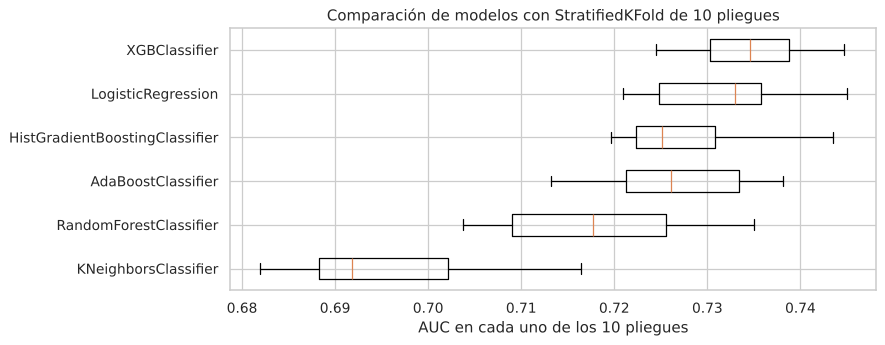

In [22]:
fig, ax = plt.subplots(figsize=(10, 4))
orden = tabla_cv.index[::-1]
ax.boxplot([resultados_cv[n]["test_auc"] for n in orden], vert=False, tick_labels=list(orden), widths=0.5)
ax.set_xlabel("AUC en cada uno de los 10 pliegues")
ax.set_title("Comparación de modelos con StratifiedKFold de 10 pliegues")
plt.tight_layout()
mejor_nombre, segundo = tabla_cv.index[0], tabla_cv.index[1]
estadistico, p_valor = stats.wilcoxon(resultados_cv[mejor_nombre]["test_auc"], resultados_cv[segundo]["test_auc"])
print(f"Prueba de Wilcoxon {mejor_nombre} vs {segundo}: diferencia media de AUC "
      f"{np.mean(resultados_cv[mejor_nombre]['test_auc'] - resultados_cv[segundo]['test_auc']):.4f}, p-valor {p_valor:.4f}")
print("Modelo elegido:", mejor_nombre)

Análisis: la caja de XGBClassifier está a la derecha de todas y es de las más angostas, es decir, gana en casi todos los pliegues y de forma estable. La prueba de Wilcoxon contra LogisticRegression da una diferencia media de 0.0028 en AUC con p-valor 0.0039, así que la ventaja es pequeña pero estadísticamente significativa. Se elige XGBClassifier.

# 9. Ajuste de hiperparámetros con GridSearchCV

In [23]:
# GridSearchCV sobre el mejor modelo, con StratifiedKFold de 5 pliegues.
parametrosGridSearch = {
    "XGBClassifier": {"modelo__max_depth": [3, 4, 5], "modelo__learning_rate": [0.03, 0.06],
                      "modelo__n_estimators": [200, 400], "modelo__min_child_weight": [1, 10]},
    "HistGradientBoostingClassifier": {"modelo__learning_rate": [0.03, 0.06], "modelo__max_leaf_nodes": [15, 31],
                                       "modelo__min_samples_leaf": [20, 100], "modelo__max_iter": [200, 400]},
    "LogisticRegression": {"modelo__C": [0.01, 0.03, 0.1, 0.3, 1.0], "modelo__class_weight": [None, "balanced"]},
    "RandomForestClassifier": {"modelo__min_samples_leaf": [2, 5, 15], "modelo__max_features": ["sqrt", 0.3]},
    "AdaBoostClassifier": {"modelo__n_estimators": [100, 200, 400], "modelo__learning_rate": [0.3, 0.6, 1.0]},
    "KNeighborsClassifier": {"modelo__n_neighbors": [35, 75, 150], "modelo__weights": ["uniform", "distance"]},
}
stratifiedKFold5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
estimador_mejor, pca_mejor = modelos[mejor_nombre]
busquedaGridSearch = GridSearchCV(crear_pipeline(estimador_mejor, pca_global=pca_mejor), parametrosGridSearch[mejor_nombre],
                                  scoring="roc_auc", cv=stratifiedKFold5, n_jobs=1, return_train_score=True).fit(X_train, y_train)
resultados_grid = pd.DataFrame(busquedaGridSearch.cv_results_)
print(f"Combinaciones evaluadas: {len(resultados_grid)} | mejor AUC: {busquedaGridSearch.best_score_:.4f} | "
      f"rango: {resultados_grid['mean_test_score'].min():.4f} a {resultados_grid['mean_test_score'].max():.4f}")
print("Mejores hiperparámetros:", {k.replace("modelo__", ""): v for k, v in busquedaGridSearch.best_params_.items()})
print(f"AUC en entrenamiento del mejor candidato: {resultados_grid.loc[busquedaGridSearch.best_index_, 'mean_train_score']:.4f}")
columnas_param = [c for c in resultados_grid.columns if c.startswith("param_")]
resultados_grid[columnas_param + ["mean_test_score", "std_test_score", "mean_train_score"]].sort_values(
    "mean_test_score", ascending=False).head(8).rename(columns=lambda c: c.replace("param_modelo__", "")).round(4)

Combinaciones evaluadas: 24 | mejor AUC: 0.7356 | rango: 0.7261 a 0.7356
Mejores hiperparámetros: {'learning_rate': 0.06, 'max_depth': 3, 'min_child_weight': 10, 'n_estimators': 400}
AUC en entrenamiento del mejor candidato: 0.7953


,learning_rate,max_depth,min_child_weight,n_estimators,mean_test_score,std_test_score,mean_train_score
15,0.06,3,10,400,0.7356,0.0049,0.7953
13,0.06,3,1,400,0.7351,0.0058,0.8010
5,0.03,4,1,400,0.7337,0.0056,0.8099
3,0.03,3,10,400,0.7335,0.0065,0.7705
11,0.03,5,10,400,0.7335,0.0045,0.8333
20,0.06,5,1,200,0.7334,0.0052,0.8530
1,0.03,3,1,400,0.7333,0.0066,0.7733
7,0.03,4,10,400,0.7333,0.0060,0.8001


Análisis: de las 24 combinaciones, la mejor usa árboles de profundidad 3, tasa de aprendizaje 0.06, peso mínimo por hoja de 10 y 400 árboles, con AUC de 0.7356. Todo el rango va de 0.7261 a 0.7356, así que el modelo es poco sensible a los hiperparámetros. El AUC de entrenamiento (0.7953) es mayor que el de validación cruzada, una diferencia moderada de sobreajuste que los árboles poco profundos ayudan a contener.

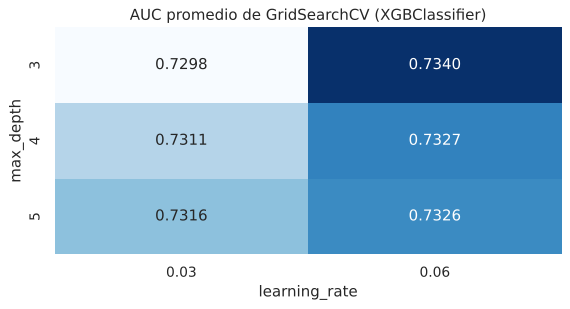

In [24]:
# AUC promedio de GridSearchCV según los dos primeros hiperparámetros de la búsqueda (promediando el resto).
param_fila, param_col = list(parametrosGridSearch[mejor_nombre])[:2]
mapa_grid = resultados_grid.assign(**{c: resultados_grid[c].astype(str) for c in columnas_param}).pivot_table(
    index=f"param_{param_fila}", columns=f"param_{param_col}", values="mean_test_score", aggfunc="mean")
fig, ax = plt.subplots(figsize=(6.5, 3.6))
sns.heatmap(mapa_grid, annot=True, fmt=".4f", cmap="Blues", ax=ax, cbar=False)
ax.set_ylabel(param_fila.replace("modelo__", ""))
ax.set_xlabel(param_col.replace("modelo__", ""))
ax.set_title(f"AUC promedio de GridSearchCV ({mejor_nombre})")
plt.tight_layout()

Análisis: el mapa promedia el resto de hiperparámetros. La tasa de aprendizaje de 0.06 supera a la de 0.03 en todas las profundidades y la mejor combinación es profundidad 3 con 0.06 (0.7340). Los árboles más profundos no ayudan: el riesgo se explica bien sumando efectos simples de cada variable.

In [25]:
# En df_val: AUC del modelo ajustado frente al modelo sin ajustar, y umbral de alerta con el índice de Youden.
pipelineFinal = busquedaGridSearch.best_estimator_
prob_val = pipelineFinal.predict_proba(X_val)[:, 1]
pipelineSinAjuste = crear_pipeline(clone(estimador_mejor), pca_global=pca_mejor).fit(X_train, y_train)
auc_val, auc_val_sin = roc_auc_score(y_val, prob_val), roc_auc_score(y_val, pipelineSinAjuste.predict_proba(X_val)[:, 1])
fpr, tpr, umbrales = roc_curve(y_val, prob_val)
UMBRAL = float(umbrales[np.argmax(tpr - fpr)])
pred_val = (prob_val >= UMBRAL).astype(int)
print(f"AUC en df_val: ajustado {auc_val:.4f} | sin ajustar {auc_val_sin:.4f} | diferencia frente a GridSearchCV {busquedaGridSearch.best_score_ - auc_val:+.4f}")
print(f"Umbral de alerta: {UMBRAL:.3f} | recall {recall_score(y_val, pred_val):.3f} | precision {precision_score(y_val, pred_val):.3f}")

AUC en df_val: ajustado 0.7429 | sin ajustar 0.7398 | diferencia frente a GridSearchCV -0.0074
Umbral de alerta: 0.518 | recall 0.719 | precision 0.688


Análisis: en df_val el modelo ajustado alcanza 0.7429 de AUC, frente a 0.7398 sin ajustar, y queda incluso por encima del valor de GridSearchCV, así que no hay señal de que la búsqueda haya sobreestimado el resultado. El umbral de alerta que mejor equilibra eventos detectados y falsas alarmas (índice de Youden) es 0.518: con él se detecta el 71.9% de los eventos y el 68.8% de las alertas son correctas. El umbral se fija aquí, antes de ver df_test.

# 10. Evaluación final en df_test

df_test se usa una sola vez, con el modelo y el umbral ya decididos.

In [26]:
# Evaluación final en df_test, que no se usó en ningún paso anterior.
prob_test = pipelineFinal.predict_proba(X_test)[:, 1]
pred_test = (prob_test >= UMBRAL).astype(int)
resumen_test = pd.Series({
    "AUC-ROC": roc_auc_score(y_test, prob_test), "average precision": average_precision_score(y_test, prob_test),
    "F1 macro": f1_score(y_test, pred_test, average="macro"), "balanced accuracy": balanced_accuracy_score(y_test, pred_test),
    "recall del evento": recall_score(y_test, pred_test), "precision del evento": precision_score(y_test, pred_test),
    "Brier score": brier_score_loss(y_test, prob_test)}, name=mejor_nombre)
print(classification_report(y_test, pred_test, target_names=["Sin evento", "Evento en 12 meses"], digits=3))
resumen_test.round(4).to_frame()

                    precision    recall  f1-score   support

        Sin evento      0.669     0.637     0.653      2029
Evento en 12 meses      0.687     0.717     0.702      2256

          accuracy                          0.679      4285
         macro avg      0.678     0.677     0.677      4285
      weighted avg      0.679     0.679     0.679      4285



,XGBClassifier
AUC-ROC,0.7425
average precision,0.7460
F1 macro,0.6773
balanced accuracy,0.6770
recall del evento,0.7168
precision del evento,0.6872
Brier score,0.2045


Análisis: en los 4,285 pacientes de df_test el AUC es 0.7425, prácticamente igual al de validación cruzada (0.7342) y al de df_val (0.7429), lo que confirma que el resultado es estable. Con el umbral de 0.518 el modelo detecta el 71.7% de los eventos (recall) y el 68.7% de sus alertas son correctas (precision). El Brier score de 0.2045 está por debajo de 0.25, que es lo que daría predecir siempre 50%.

## 10.1 Matriz de confusión y curvas

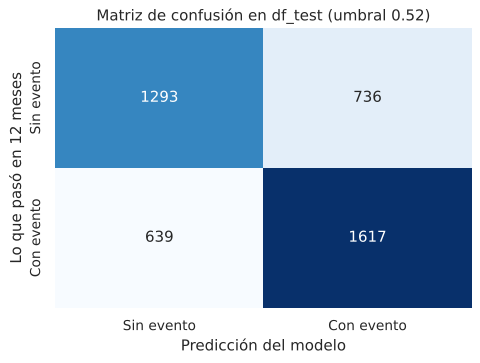

In [27]:
fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.heatmap(confusion_matrix(y_test, pred_test), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Sin evento", "Con evento"], yticklabels=["Sin evento", "Con evento"])
ax.set_xlabel("Predicción del modelo")
ax.set_ylabel("Lo que pasó en 12 meses")
ax.set_title(f"Matriz de confusión en df_test (umbral {UMBRAL:.2f})")
plt.tight_layout()

Análisis: de los 2,256 pacientes que sí tuvieron un evento, el modelo alertó a 1,617 y no detectó a 639. De los 2,029 sin evento, 1,293 quedaron bien clasificados y 736 recibieron una alerta de más. En la práctica, un falso negativo es un paciente de alto riesgo con seguimiento habitual y un falso positivo es un control adicional; si el equipo prefiere detectar más eventos, puede bajar el umbral a cambio de más alertas.

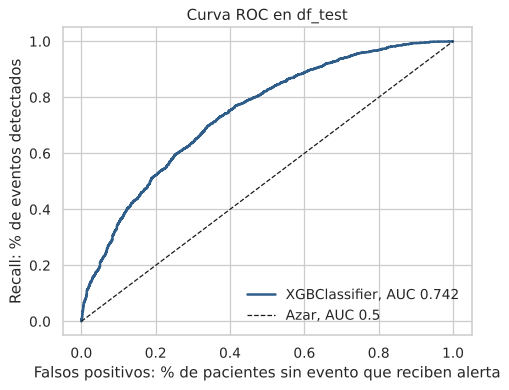

In [28]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
f, t, _ = roc_curve(y_test, prob_test)
ax.plot(f, t, color=AZUL, linewidth=2, label=f"{mejor_nombre}, AUC {roc_auc_score(y_test, prob_test):.3f}")
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Azar, AUC 0.5")
ax.set_xlabel("Falsos positivos: % de pacientes sin evento que reciben alerta")
ax.set_ylabel("Recall: % de eventos detectados")
ax.set_title("Curva ROC en df_test")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()

Análisis: la curva queda muy por encima de la diagonal del azar en todo su recorrido. Cada punto es un umbral posible: por ejemplo, para detectar cerca del 80% de los eventos hay que aceptar que cerca de la mitad de los pacientes sin evento reciba una alerta. El AUC de 0.742 resume esa capacidad de ordenar a los pacientes por riesgo.

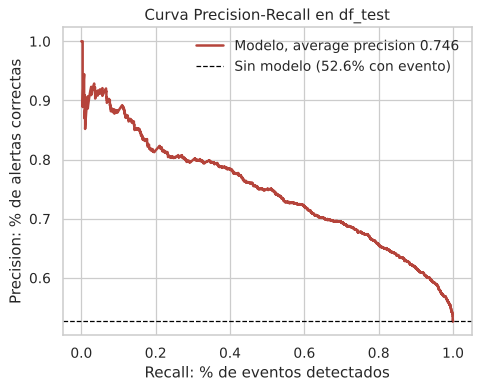

In [29]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
pr, rc, _ = precision_recall_curve(y_test, prob_test)
ax.plot(rc, pr, color=ROJO, linewidth=2, label=f"Modelo, average precision {average_precision_score(y_test, prob_test):.3f}")
ax.axhline(y_test.mean(), color="black", linestyle="--", linewidth=1, label=f"Sin modelo ({y_test.mean():.1%} con evento)")
ax.set_xlabel("Recall: % de eventos detectados")
ax.set_ylabel("Precision: % de alertas correctas")
ax.set_title("Curva Precision-Recall en df_test")
ax.legend(frameon=False)
plt.tight_layout()

Análisis: sin modelo, alertar a todos daría una precision de 52.6%, la proporción de pacientes con evento. El modelo mantiene una precision de 80% o más mientras detecta hasta cerca del 30% de los eventos, que son los pacientes de mayor riesgo. El average precision de 0.746 está muy por encima de esa línea base.

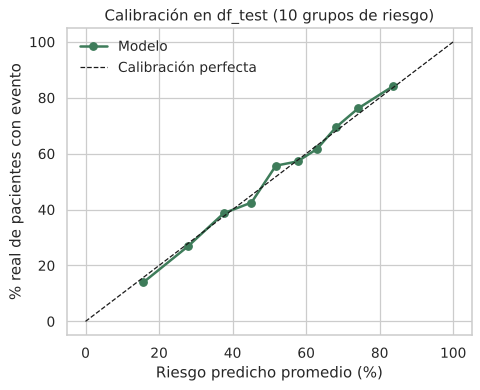

In [30]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
frac_real, prob_media = calibration_curve(y_test, prob_test, n_bins=10, strategy="quantile")
ax.plot(prob_media * 100, frac_real * 100, marker="o", color=VERDE, linewidth=2, label="Modelo")
ax.plot([0, 100], [0, 100], "k--", linewidth=1, label="Calibración perfecta")
ax.set_xlabel("Riesgo predicho promedio (%)")
ax.set_ylabel("% real de pacientes con evento")
ax.set_title("Calibración en df_test (10 grupos de riesgo)")
ax.legend(frameon=False)
plt.tight_layout()

Análisis: los puntos siguen de cerca la diagonal en todo el rango, de 16% a 84% de riesgo predicho. Esto significa que las probabilidades se pueden leer de forma literal: entre los pacientes a los que el modelo les asigna cerca de 40% de riesgo, alrededor de 4 de cada 10 tienen un evento.

## 10.2 Riesgo por deciles

Decil de menor riesgo: 14.0% | decil de mayor riesgo: 84.1% | 6.0 veces más


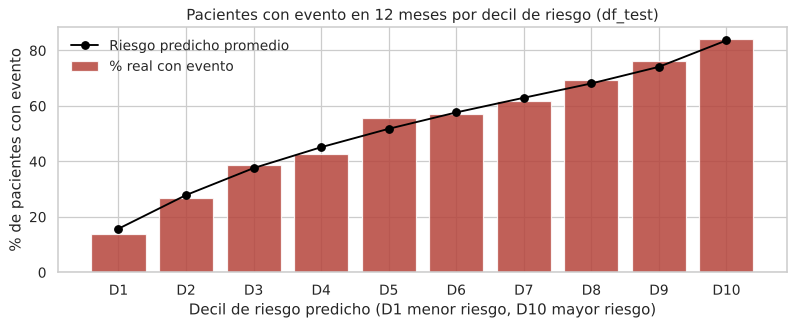

,pacientes,riesgo_medio_predicho,tasa_real_de_evento
decil,,,
D1,429,0.157,0.140
D2,428,0.279,0.269
D3,429,0.376,0.387
D4,428,0.451,0.425
D5,429,0.518,0.557
D6,428,0.577,0.572
D7,428,0.630,0.617
D8,429,0.681,0.695
D9,428,0.741,0.762


In [31]:
# Porcentaje real de pacientes con evento por decil de riesgo predicho en df_test.
tabla_deciles = pd.DataFrame({"riesgo": prob_test, "evento": y_test.values,
                              "decil": pd.qcut(prob_test, 10, labels=[f"D{i}" for i in range(1, 11)])}).groupby(
    "decil", observed=True).agg(pacientes=("evento", "size"), riesgo_medio_predicho=("riesgo", "mean"), tasa_real_de_evento=("evento", "mean"))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(tabla_deciles.index.astype(str), tabla_deciles["tasa_real_de_evento"] * 100, color=ROJO, alpha=0.85, label="% real con evento")
ax.plot(tabla_deciles.index.astype(str), tabla_deciles["riesgo_medio_predicho"] * 100, color="black", marker="o", label="Riesgo predicho promedio")
ax.set_xlabel("Decil de riesgo predicho (D1 menor riesgo, D10 mayor riesgo)")
ax.set_ylabel("% de pacientes con evento")
ax.set_title("Pacientes con evento en 12 meses por decil de riesgo (df_test)")
ax.legend(frameon=False)
plt.tight_layout()
bajo, alto = tabla_deciles["tasa_real_de_evento"].iloc[0], tabla_deciles["tasa_real_de_evento"].iloc[-1]
print(f"Decil de menor riesgo: {bajo:.1%} | decil de mayor riesgo: {alto:.1%} | {alto / bajo:.1f} veces más")
tabla_deciles.round(3)

Análisis: es la lectura más útil para el equipo clínico. En el 10% de pacientes de menor riesgo, solo el 14.0% tuvo un evento en el primer año; en el 10% de mayor riesgo, el 84.1%, es decir, 6.0 veces más. La tasa real sube de forma escalonada decil a decil y coincide con el riesgo predicho. Esto permite definir tres niveles: bajo (deciles 1 a 3, de 14% a 39%), intermedio y alto (deciles 8 a 10, de 70% a 84%).

## 10.3 Desempeño por grupo racial

La competencia pide que el modelo funcione de forma equitativa entre grupos raciales. Su métrica oficial es el C-index estratificado: el promedio del C-index de cada grupo menos su desviación estándar, así que penaliza las diferencias entre grupos.

In [32]:
# Desempeño por grupo racial (el modelo no usa esta variable) y C-index estratificado, la métrica de la competencia.
def c_index(tiempo, evento, riesgo):
    t, e, r = np.asarray(tiempo), np.asarray(evento), np.asarray(riesgo)
    comparables = (t[:, None] < t[None, :]) & (e[:, None] == 1)
    return (((r[:, None] > r[None, :]) & comparables).sum() + 0.5 * ((r[:, None] == r[None, :]) & comparables).sum()) / comparables.sum()

filas = []
for grupo, indices in df_test.groupby("grupo_racial").groups.items():
    pos = df_test.index.get_indexer(indices)
    filas.append({"grupo": grupo, "pacientes": len(pos), "% con evento": y_test.values[pos].mean() * 100,
                  "AUC": roc_auc_score(y_test.values[pos], prob_test[pos]), "recall del evento": recall_score(y_test.values[pos], pred_test[pos]),
                  "C-index": c_index(df_test.iloc[pos]["meses_hasta_evento"], df_test.iloc[pos]["evento"], prob_test[pos])})
tabla_equidad = pd.DataFrame(filas).set_index("grupo")
c_estratificado = tabla_equidad["C-index"].mean() - tabla_equidad["C-index"].std(ddof=0)
print(f"C-index estratificado: {c_estratificado:.4f} | AUC entre grupos: {tabla_equidad['AUC'].min():.3f} a {tabla_equidad['AUC'].max():.3f}")
tabla_equidad.round(3)

C-index estratificado: 0.6464 | AUC entre grupos: 0.729 a 0.756


,pacientes,% con evento,AUC,recall del evento,C-index
grupo,,,,,
American Indian or Alaska Native,710,49.718,0.739,0.700,0.661
Asian,722,54.155,0.745,0.762,0.678
Black or African-American,715,55.105,0.756,0.685,0.667
More than one race,717,44.491,0.731,0.614,0.660
Native Hawaiian or other Pacific Islander,698,51.146,0.729,0.703,0.656
White,723,61.134,0.731,0.803,0.635


Análisis: el modelo no usa la raza y aun así funciona parecido en los seis grupos, con AUC entre 0.729 y 0.756 y C-index entre 0.635 y 0.678. El C-index estratificado de la competencia es 0.6464. El recall cambia más (de 0.614 en el grupo de más de una raza a 0.803 en el grupo blanco), pero sigue a la proporción de eventos de cada grupo (44.5% y 61.1%): donde hay más eventos, un mismo umbral detecta más.

## 10.4 Desempeño por subgrupo clínico

In [33]:
# Desempeño por subgrupo clínico en df_test, para saber dónde el modelo es más o menos confiable.
df_resultados = df_test.assign(prob=prob_test, pred=pred_test)
df_resultados["grupo_edad"] = pd.cut(df_resultados["edad_paciente"], [-1, 17.99, 40, 60, 100],
                                     labels=["Menor de 18", "18 a 40", "40 a 60", "Mayor de 60"]).astype(str)
def resumen_por(col):
    filas = [{col: v, "pacientes": len(g), "% con evento": g["evento_12m"].mean() * 100, "AUC": roc_auc_score(g["evento_12m"], g["prob"]),
              "recall del evento": recall_score(g["evento_12m"], g["pred"])}
             for v, g in df_resultados.groupby(col) if len(g) >= 80]
    return pd.DataFrame(filas).set_index(col).round(3)
display(resumen_por("grupo_edad"))
resumen_por("tipo_injerto")

,pacientes,% con evento,AUC,recall del evento
grupo_edad,,,,
18 a 40,1051,53.283,0.706,0.668
40 a 60,1332,59.084,0.704,0.812
Mayor de 60,860,63.953,0.700,0.851
Menor de 18,1042,34.453,0.746,0.379


,pacientes,% con evento,AUC,recall del evento
tipo_injerto,,,,
Bone marrow,1236,35.113,0.737,0.346
Peripheral blood,3049,59.757,0.708,0.805


Análisis: el modelo ordena bien el riesgo en todos los grupos de edad (AUC de 0.700 a 0.746), y mejor aún en los menores de 18. El punto débil es el umbral: en los niños, que tienen un riesgo base mucho menor (34.5% con evento), el umbral general solo detecta el 37.9% de sus eventos. Lo mismo pasa con el injerto de médula ósea (recall de 0.346), un grupo que también tiene un riesgo base bajo (35.1% con evento). Para pacientes pediátricos conviene un umbral propio más bajo.

# 11. Análisis a 6, 12 y 18 meses

Para revisar si el horizonte de 12 meses fue una buena elección, se repite el entrenamiento con el evento a 6 y a 18 meses.

In [34]:
# El mismo pipeline (con los hiperparámetros elegidos) entrenado para predecir el evento a 6, 12 y 18 meses.
# Se usan solo los pacientes que no están en df_test, con StratifiedKFold de 5 pliegues.
df_sin_test = df_clean[~df_clean["id"].isin(df_test["id"])]
filas = []
for h in (6, 12, 18):
    df_h = construir_objetivo(df_sin_test, h)
    auc = cross_validate(clone(pipelineFinal), df_h[COLUMNAS_ENTRADA], df_h["evento_12m"], cv=stratifiedKFold5, scoring="roc_auc")["test_score"]
    filas.append({"horizonte (meses)": h, "pacientes": len(df_h),
                  "% excluidos por censura": ((df_clean["evento"] == 0) & (df_clean["meses_hasta_evento"] < h)).mean() * 100,
                  "% con evento en el horizonte": df_h["evento_12m"].mean() * 100, "AUC (media)": auc.mean(), "AUC (desv.)": auc.std()})
tabla_horizontes = pd.DataFrame(filas).set_index("horizonte (meses)")
tabla_horizontes.round(3)

,pacientes,% excluidos por censura,% con evento en el horizonte,AUC (media),AUC (desv.)
horizonte (meses),,,,,
6,24496,0.066,29.066,0.735,0.005
12,24277,0.826,52.626,0.737,0.004
18,23589,3.764,55.602,0.738,0.009


Análisis: el modelo rinde igual en los tres horizontes (AUC de 0.735, 0.737 y 0.738), así que la elección se basa en el problema y no en la métrica. A 6 meses solo el 29.1% de los pacientes tiene evento, porque se pierde casi la mitad de los que ocurren en el primer año. A 18 meses la proporción casi no sube (55.6% frente a 52.6%), pero se excluye el 3.8% de los pacientes por censura, cuatro veces y media más que a 12 meses. El horizonte de 12 meses captura casi todos los eventos con la menor pérdida de pacientes, así que no hay un sesgo relevante por haberlo elegido.

# 12. Explicabilidad con SHAP

SHAP reparte la predicción de cada paciente entre sus variables: cuánto sube o baja el riesgo cada una frente al riesgo promedio. Se calcula sobre 1,000 pacientes de df_val con el modelo final.

In [35]:
# SHAP sobre el mejor modelo. Los valores se calculan en las columnas que ve el modelo (One-Hot y componentes HLA)
# y luego se suman por variable original, para explicar en el lenguaje del registro clínico.
columnTransformer = pipelineFinal.named_steps["columnTransformer"]
estimador_final = pipelineFinal.named_steps["modelo"]
nombres_columnas = columnTransformer.get_feature_names_out()
X_shap = X_val.sample(1000, random_state=SEMILLA)
X_shap_transformado = columnTransformer.transform(X_shap)
if mejor_nombre == "LogisticRegression":
    explicadorShap = shap.LinearExplainer(estimador_final, columnTransformer.transform(X_train.sample(500, random_state=SEMILLA)))
else:
    explicadorShap = shap.TreeExplainer(estimador_final)
valores_shap = explicadorShap(X_shap_transformado)
if valores_shap.values.ndim == 3:
    valores_shap = valores_shap[:, :, 1]

def variable_original(nombre):
    bloque, resto = nombre.split("__", 1)
    if bloque == "hla":
        return "compatibilidad_hla"
    if bloque == "num":
        return resto
    return next(c for c in sorted(COLUMNAS_CATEGORICAS, key=len, reverse=True) if resto.startswith(c + "_"))

df_shap = pd.DataFrame(valores_shap.values, columns=[variable_original(n) for n in nombres_columnas]).T.groupby(level=0).sum().T
valor_base = float(np.atleast_1d(valores_shap.base_values)[0])
print(f"Pacientes explicados: {len(X_shap)} | columnas del modelo: {len(nombres_columnas)} | variables originales: {df_shap.shape[1]}")
print(f"Valor base: {valor_base:.3f} en log-odds, que equivale a un riesgo de {1 / (1 + np.exp(-valor_base)):.1%}")

Pacientes explicados: 1000 | columnas del modelo: 181 | variables originales: 41
Valor base: 0.105 en log-odds, que equivale a un riesgo de 52.6%


Análisis: SHAP calcula una contribución para cada una de las 181 columnas del modelo y esas contribuciones se suman en las 41 variables originales; los 28 componentes HLA quedan juntos como compatibilidad_hla. El punto de partida (valor base) es 0.105 en log-odds, que equivale al 52.6% de riesgo promedio. Cada paciente parte de ahí y sus variables lo suben o lo bajan.

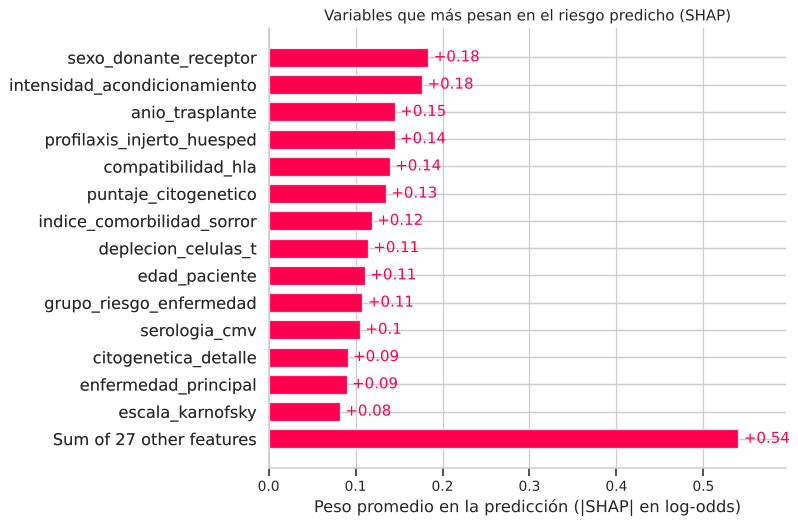

,SHAP medio absoluto
sexo_donante_receptor,0.1836
intensidad_acondicionamiento,0.1765
anio_trasplante,0.1451
profilaxis_injerto_huesped,0.1448
compatibilidad_hla,0.1393
puntaje_citogenetico,0.1348
indice_comorbilidad_sorror,0.1186
deplecion_celulas_t,0.1140
edad_paciente,0.1107
grupo_riesgo_enfermedad,0.1079


In [36]:
# Importancia global: promedio del valor absoluto de SHAP de cada variable original.
importancia_shap = df_shap.abs().mean().sort_values(ascending=False)
datos_color = X_shap.assign(compatibilidad_hla=pd.to_numeric(X_shap["hla_alta_res_8"], errors="coerce"))
explicacion = shap.Explanation(values=df_shap[importancia_shap.index].values, base_values=np.full(len(df_shap), valor_base),
                               data=datos_color[importancia_shap.index].apply(pd.to_numeric, errors="coerce").values,
                               feature_names=list(importancia_shap.index))
shap.plots.bar(explicacion, max_display=15, show=False)
plt.gcf().set_size_inches(9, 6)
plt.xlabel("Peso promedio en la predicción (|SHAP| en log-odds)")
plt.title("Variables que más pesan en el riesgo predicho (SHAP)")
plt.tight_layout()
importancia_shap.head(15).round(4).rename("SHAP medio absoluto").to_frame()

Análisis: las variables que más pesan son la combinación de sexos de donante y receptor, la intensidad del acondicionamiento, el año del trasplante, la profilaxis contra la enfermedad injerto contra huésped y la compatibilidad HLA, seguidas de la citogenética, el índice de Sorror, la depleción de células T y la edad. Son factores que el equipo médico ya conoce, lo que da confianza en que el modelo aprendió relaciones clínicas y no ruido.

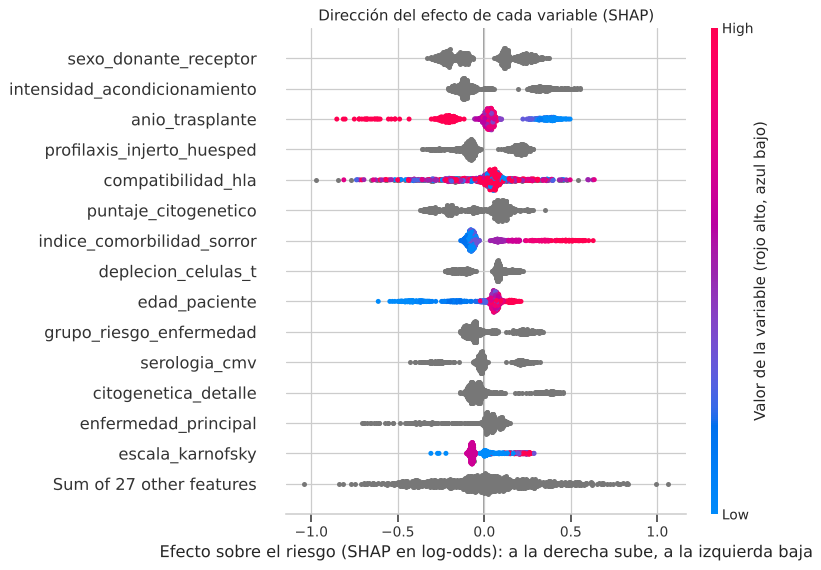

In [37]:
# Beeswarm: cada punto es un paciente. A la derecha la variable sube el riesgo, a la izquierda lo baja.
# El color indica el valor de las variables numéricas (rojo alto, azul bajo); las categóricas salen en gris.
shap.plots.beeswarm(explicacion, max_display=15, show=False)
figura = plt.gcf()
figura.set_size_inches(9, 6.5)
figura.axes[0].set_xlabel("Efecto sobre el riesgo (SHAP en log-odds): a la derecha sube, a la izquierda baja")
if len(figura.axes) > 1:
    figura.axes[-1].set_ylabel("Valor de la variable (rojo alto, azul bajo)")
plt.title("Dirección del efecto de cada variable (SHAP)")
plt.tight_layout()

Análisis: la dirección de cada efecto tiene sentido. Los trasplantes más recientes (rojo) quedan a la izquierda, con menos riesgo, lo que refleja la mejora de los protocolos con los años. Un índice de Sorror alto (rojo) sube el riesgo y uno bajo lo baja. En la edad, los pacientes más jóvenes (azul) tienen las contribuciones más negativas. Las variables categóricas aparecen en gris y se detallan en la siguiente gráfica.

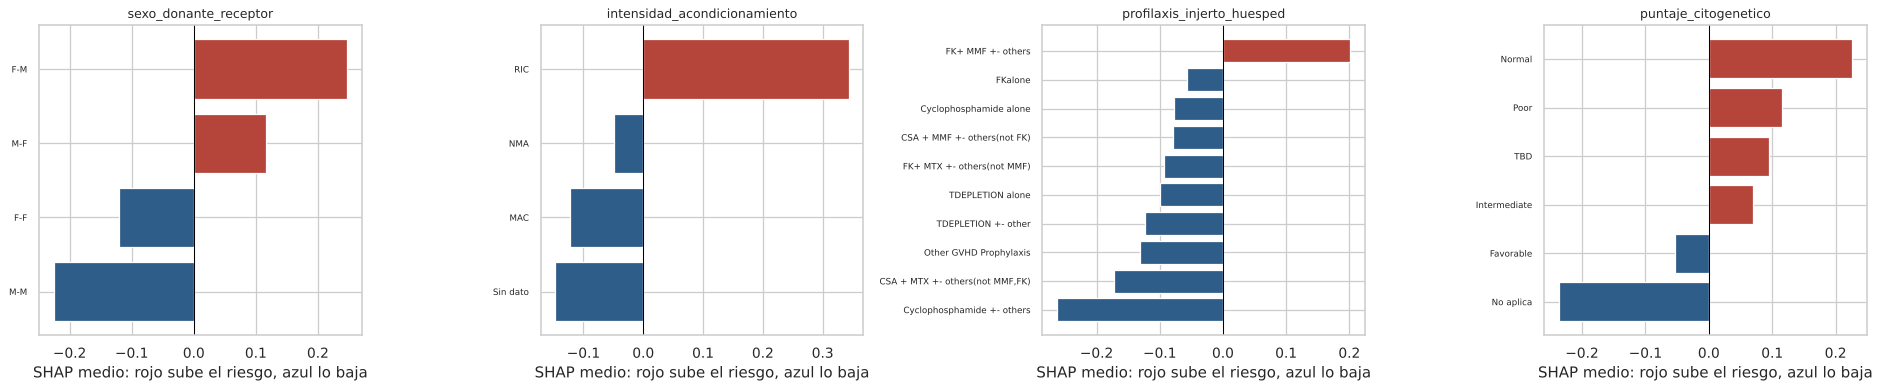

In [38]:
# SHAP medio por categoría en las cuatro variables categóricas más importantes.
top_categoricas = [c for c in importancia_shap.index if c in COLUMNAS_CATEGORICAS][:4]
fig, axes = plt.subplots(1, 4, figsize=(21, 4.5))
for ax, col in zip(axes, top_categoricas):
    media = df_shap[col].groupby(X_shap[col].fillna("Sin dato").values).agg(["mean", "size"])
    media = media[media["size"] >= 15].sort_values("mean")
    ax.barh(media.index.astype(str), media["mean"], color=[ROJO if v > 0 else AZUL for v in media["mean"]])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("SHAP medio: rojo sube el riesgo, azul lo baja")
    ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()

Análisis: donante mujer con receptor hombre (F-M) es la combinación que más sube el riesgo y donante y receptor hombres (M-M) la que más lo baja. El acondicionamiento de intensidad reducida (RIC) sube el riesgo, porque se usa en pacientes más frágiles, y el intenso (MAC) lo baja; los pacientes sin dato reciben el valor más frecuente (MAC) y por eso se comportan igual. En la profilaxis, tacrolimus con micofenolato (FK + MMF) sube el riesgo y los esquemas con ciclofosfamida, los más modernos, lo bajan. En la citogenética, los resultados normal, de mal pronóstico, intermedio o pendiente suben el riesgo, el favorable lo baja, y No aplica lo baja aún más, porque corresponde sobre todo a enfermedades no malignas en las que esa prueba no se hace.

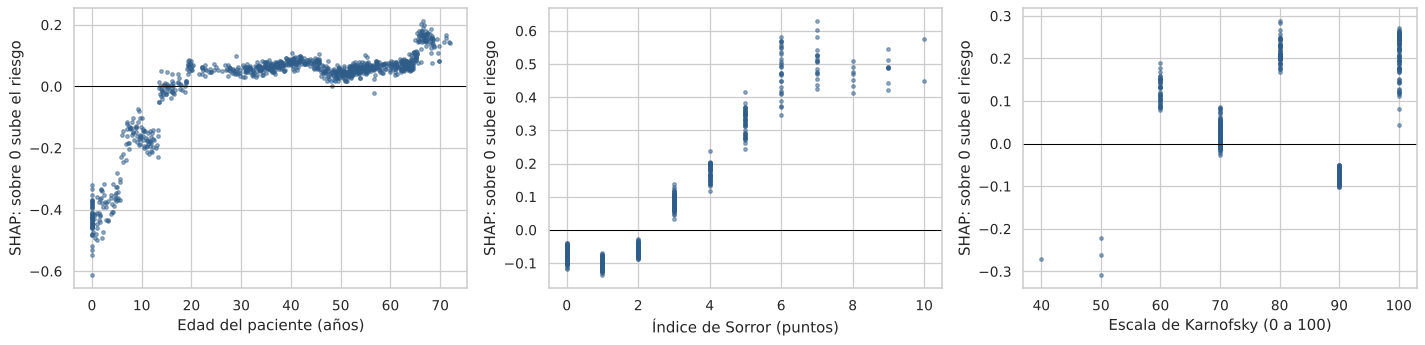

In [39]:
# Dependencia: cómo cambia la contribución de tres variables numéricas según su valor.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (col, titulo) in zip(axes, {"edad_paciente": "Edad del paciente (años)", "indice_comorbilidad_sorror": "Índice de Sorror (puntos)",
                                     "escala_karnofsky": "Escala de Karnofsky (0 a 100)"}.items()):
    ax.scatter(X_shap[col], df_shap[col], s=8, alpha=0.5, color=AZUL)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xlabel(titulo)
    ax.set_ylabel("SHAP: sobre 0 sube el riesgo")
plt.tight_layout()

Análisis: en la edad, los niños pequeños tienen la contribución más negativa (hasta -0.6), el efecto cruza el cero cerca de los 15 a 18 años, se mantiene estable en los adultos y vuelve a subir después de los 63. En el índice de Sorror el patrón es casi una escalera: de 0 a 2 puntos baja el riesgo, desde 3 lo sube y desde 6 se estabiliza en el valor más alto. La escala de Karnofsky no muestra un patrón ordenado (60 y 80 suben el riesgo, 90 lo baja y 100 lo sube), así que su efecto depende de otras variables y no debe leerse por sí sola.

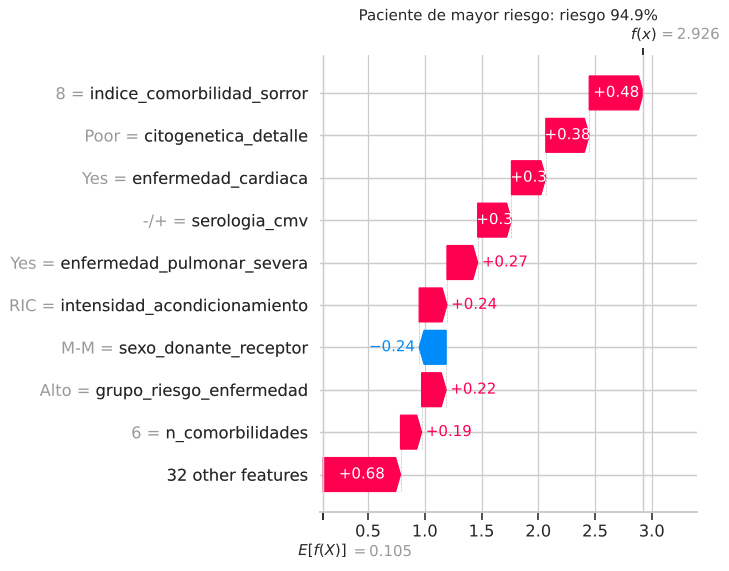

In [40]:
# Explicación individual del paciente con mayor riesgo de la muestra.
prob_shap = pipelineFinal.predict_proba(X_shap)[:, 1]
def explicar_paciente(posicion, titulo):
    fila = df_shap.iloc[posicion]
    hla8 = X_shap.iloc[posicion]["hla_alta_res_8"]
    valores = [(hla8 if hla8 == "No aplica" else f"{hla8} de 8") if c == "compatibilidad_hla" else X_shap.iloc[posicion].get(c, "") for c in fila.index]
    plt.figure(figsize=(9, 5))
    shap.plots.waterfall(shap.Explanation(values=fila.values, base_values=valor_base, data=np.array(valores, dtype=object),
                                          feature_names=list(fila.index)), max_display=10, show=False)
    plt.title(f"{titulo}: riesgo {prob_shap[posicion]:.1%}")
    plt.tight_layout()
explicar_paciente(int(np.argmax(prob_shap)), "Paciente de mayor riesgo")

Análisis: este paciente tiene un riesgo de 94.9%. Parte del 52.6% promedio y lo que más lo empuja hacia arriba es un índice de Sorror de 8, una citogenética de mal pronóstico, enfermedad cardíaca, serología de citomegalovirus negativa en el donante y positiva en el receptor, enfermedad pulmonar severa y acondicionamiento de intensidad reducida. La combinación de sexos M-M es lo único relevante que le baja el riesgo. Este tipo de gráfico es el que se muestra en la aplicación para explicar cada caso.

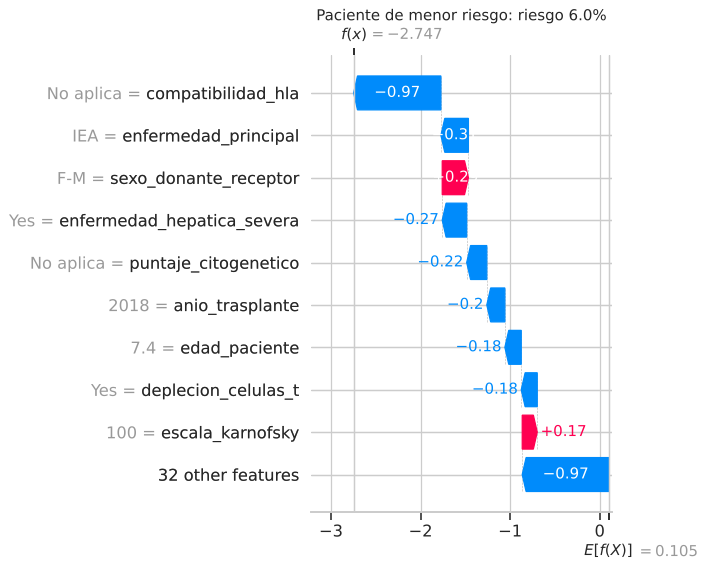

In [41]:
# Explicación individual del paciente con menor riesgo de la muestra.
explicar_paciente(int(np.argmin(prob_shap)), "Paciente de menor riesgo")

Análisis: este paciente tiene un riesgo de 6.0%. Es un niño de 7 años con una anomalía hereditaria de los eritrocitos (IEA), sin registro de compatibilidad HLA ni de citogenética, trasplantado en 2018 y con depleción de células T. La contribución más grande viene de la compatibilidad HLA en No aplica (-0.97): en estos pacientes la falta de registro genético coincide con un perfil de bajo riesgo. Es un efecto de la regla de marcar No aplica, que conviene vigilar si el modelo se usa en centros donde la tipificación HLA siempre se registra.

# 13. Exportación del modelo

In [42]:
# Exportación para el despliegue. El pipeline final se reentrena con todo df_model y los hiperparámetros elegidos.
# Solo contiene clases estándar de scikit-learn y XGBoost, así que se carga con joblib sin pasos adicionales.
carpeta = Path("artefactos")
carpeta.mkdir(exist_ok=True)
pipelineDespliegue = clone(pipelineFinal).fit(df_model[COLUMNAS_ENTRADA], df_model["evento_12m"])
joblib.dump(pipelineDespliegue, carpeta / "modelo_hct.joblib")
df_raw.drop(columns=["efs", "efs_time"]).sample(200, random_state=SEMILLA).to_csv(carpeta / "fondo_shapley.csv", index=False)
df_raw.drop(columns=["efs", "efs_time"]).sample(5, random_state=7).to_csv(carpeta / "pacientes_ejemplo.csv", index=False)

# Variables que se piden en el formulario de la aplicación: las de df_raw que llegan al modelo, antes de la limpieza.
df_formulario = df_raw.rename(columns=NOMBRES).drop(columns=COLUMNAS_ELIMINADAS + COLUMNAS_PROTEGIDAS + ["id", "evento", "meses_hasta_evento"])
a_python = lambda v: float(v) if isinstance(v, (np.floating, float)) else int(v) if isinstance(v, (np.integer, int)) else v
metadatos = {
    "modelo": mejor_nombre, "hiperparametros": {k.replace("modelo__", ""): a_python(v) for k, v in busquedaGridSearch.best_params_.items()},
    "umbral": UMBRAL, "nombres_originales": NOMBRES, "columnas_eliminadas": COLUMNAS_ELIMINADAS,
    "variables_geneticas": VARIABLES_GENETICAS, "columnas_entrada": COLUMNAS_ENTRADA,
    "descripciones": {NOMBRES[k]: v for k, v in descripcion_oficial.items() if k in NOMBRES and isinstance(v, str)},
    "fuente_diccionario": "https://www.kaggle.com/competitions/equity-post-HCT-survival-predictions/data",
    "variables_formulario": list(df_formulario.columns),
    "opciones": {c: sorted(df_formulario[c].dropna().astype(str).unique().tolist()) for c in df_formulario.select_dtypes(exclude="number").columns},
    "rangos": {c: [a_python(df_formulario[c].min()), a_python(df_formulario[c].median()), a_python(df_formulario[c].max())]
               for c in df_formulario.select_dtypes("number").columns},
    "metricas_prueba": {k: float(v) for k, v in resumen_test.items()}, "c_index_estratificado": float(c_estratificado),
    "equidad_prueba": tabla_equidad.reset_index().round(4).to_dict(orient="records"),
    "deciles_prueba": tabla_deciles.reset_index().astype({"decil": str}).round(4).to_dict(orient="records"),
    "importancia_shap": importancia_shap.round(5).astype(float).to_dict(),
    "tasa_base": float(df_model["evento_12m"].mean()), "pacientes_despliegue": int(len(df_model)),
    "versiones": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__,
                  "joblib": joblib.__version__, "xgboost": xgboost.__version__},
}
(carpeta / "metadatos.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=2), encoding="utf-8")
(carpeta / "requirements_modelo.txt").write_text("\n".join(f"{k}=={v}" for k, v in metadatos["versiones"].items()) + "\n", encoding="utf-8")
print("Archivos exportados:", sorted(p.name for p in carpeta.iterdir()))

Archivos exportados: ['fondo_shapley.csv', 'metadatos.json', 'modelo_hct.joblib', 'pacientes_ejemplo.csv', 'requirements_modelo.txt']


Análisis: el pipeline final se reentrena con los 28,562 pacientes de df_model y se guarda en artefactos/ junto con los metadatos que usan la API y la aplicación: umbral, reglas de limpieza, nombres de variables, opciones válidas, métricas de df_test y deciles de riesgo. Como el Pipeline solo tiene clases estándar, basta con joblib.load y la misma función limpiar_datos de la sección 3 para usarlo con un paciente nuevo.

# 14. Conclusiones

- El problema de supervivencia se convirtió en una clasificación a 12 meses porque la decisión clínica es binaria, el 96.8% de los eventos ocurre en el primer año y la censura solo obliga a excluir al 0.8% de los pacientes. Los horizontes de 6 y 18 meses dan el mismo AUC, pero pierden eventos o pacientes.
- La limpieza eliminó 2 variables con más de 50% de nulos y marcó como No aplica los vacíos de las 21 variables genéticas. El resto se imputa dentro del Pipeline con SimpleImputer, y la estrategia most_frequent evitó que el modelo premiara los formularios incompletos (de 31.9 a 6.8 puntos de cambio en el riesgo).
- PCA redujo el bloque HLA de 88 a 28 columnas sin perder capacidad. Las clases están balanceadas y ningún balanceador mejoró el AUC.
- XGBClassifier fue el mejor de seis modelos (AUC 0.7342 en validación cruzada, con diferencia significativa frente a LogisticRegression) y, ajustado con GridSearchCV, logra en df_test un AUC de 0.7425, recall de 71.7% y precision de 68.7%, con probabilidades bien calibradas.
- El modelo separa con claridad a los pacientes: 14.0% de eventos en el decil de menor riesgo y 84.1% en el de mayor riesgo. Funciona parecido en los seis grupos raciales (AUC de 0.729 a 0.756) aunque no usa la raza.
- SHAP muestra que el riesgo depende del donante (combinación de sexos, compatibilidad HLA), del tratamiento (intensidad del acondicionamiento, profilaxis), del año del trasplante y de la fragilidad del paciente (Sorror, edad).
- Siguientes pasos: un umbral propio para pacientes pediátricos, vigilar el efecto de No aplica en la compatibilidad HLA y recalibrar el modelo con datos locales antes de usarlo en otro centro.